# Desafio 3 — Segmentação de áreas verdes com a LoveDA

**Objetivo:** comparar otimizadores e taxas de aprendizado para identificar vegetação em imagens urbanas de satélite.

**Modelo:** U-Net padrão (`segmentation_models_pytorch`) com saída binária: vegetação = 1; demais classes = 0.

## Como usar este Colab
1. Envie a pasta `LoveDA` para o Google Drive, preservando as divisões `Train`, `Val` e `Test`.
2. Em cada divisão, mantenha `images_png` e `masks_png`.
3. Execute as células em ordem e confira a visualização das máscaras antes de treinar.
4. Primeiro rode o teste rápido; depois execute as etapas do Desafio 3.
5. Os resultados serão salvos na pasta `desafio3_resultados`.



## 1. Instalação e imports

In [ ]:
!pip -q install -U segmentation-models-pytorch


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 3.9 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os, re, json, time, math, random, copy, warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import segmentation_models_pytorch as smp
import hashlib
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.ticker import MaxNLocator

print("PyTorch:", torch.__version__)
print("SMP:", smp.__version__)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cpu
SMP: 0.5.0
Dispositivo: cpu


## 2. Configuração

**Edite apenas `DATASET_DIR` se a pasta tiver outro nome ou localização.** O código espera `Train/images_png`, `Train/masks_png`, `Val/...` e `Test/...`.

Em `GREEN_LABELS`, escolha quais valores das máscaras representam as áreas que você quer chamar de verdes.


In [ ]:
# ====== CAMINHO DO DATASET NO GOOGLE DRIVE ======
DATASET_DIR = "/content/drive/MyDrive/LoveDA"
OUTPUT_DIR = "/content/drive/MyDrive/desafio3_resultados"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ====== QUAIS RÓTULOS DA MÁSCARA SERÃO CONSIDERADOS ÁREA VERDE? ======
# No esquema de rótulos LoveDA: 6 = forest (floresta); 7 = agriculture (agricultura).

GREEN_LABELS = [6, 7]

# ====== DADOS E TREINO ======
IMAGE_SIZE = 256
BATCH_SIZE = 8
NUM_WORKERS = 2
BASELINE_EPOCHS = 15
SWEEP_EPOCHS = 5       # orçamento reduzido, igual para todas as configurações da varredura
FINAL_EPOCHS = 15
SEEDS = [42, 94, 168]
ENCODER_NAME = "resnet34"
ENCODER_WEIGHTS = None # opcional: "imagenet", se houver internet no Colab
LOG_EVERY_STEPS = 20
MAX_GRAD_NORM = None   # None = sem clipping

# Cinco taxas por otimizador; ajuste depois de observar os resultados.
LR_GRIDS = {
    "SGD":          [1e-3, 3e-3, 1e-2, 3e-2, 1e-1],
    "SGD_Nesterov": [1e-3, 3e-3, 1e-2, 3e-2, 1e-1],
    "Adam":         [1e-5, 3e-5, 1e-4, 3e-4, 1e-3],
    "AdamW":        [1e-5, 3e-5, 1e-4, 3e-4, 1e-3],
    "Muon":         [1e-3, 3e-3, 1e-2, 3e-2, 1e-1],
}
BASELINE_OPTIMIZER = "AdamW"
BASELINE_LR = 1e-4
BASELINE_SCHEDULE = "warmup_cosine"

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print("Dispositivo:", DEVICE)
print("Dataset:", DATASET_DIR)
print("Rótulos tratados como verdes:", GREEN_LABELS)
print("Resultados serão salvos em:", OUTPUT_DIR)


Dispositivo: cpu
Dataset: /content/drive/MyDrive/LoveDA
Rótulos tratados como verdes: [6, 7]
Resultados serão salvos em: /content/drive/MyDrive/desafio3_resultados


## 3. Carregamento do dataset LoveDA

As imagens e máscaras rotuladas das pastas `Train/Urban` e `Val/Urban` são reunidas para formar um único conjunto de exemplos. Em seguida, os pares válidos são divididos em treino (70%), validação (15%) e teste (15%), com semente fixa (`random_state=42`).

A divisão é salva em `split_fixo.json` para que os mesmos exemplos sejam utilizados em todos os experimentos. As imagens da pasta `Test` original não são utilizadas, pois não possuem máscaras disponíveis para avaliação.

A classe `SatelliteSegmentationDataset` transforma a máscara multiclasse em uma máscara binária: pixels cujos valores estão em `GREEN_LABELS` recebem valor 1; os demais recebem valor 0.

In [ ]:
def normalize_name(path):
    """Remove o sufixo de cópia, como '(1)', para tentar correspondência."""
    stem = Path(path).stem.lower()
    return re.sub(r"\s*\(\d+\)$", "", stem)


def file_hash(path):
    """Calcula o hash do conteúdo do arquivo."""
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            digest.update(chunk)

    return digest.hexdigest()


def collect_labeled_pairs(split_names=("Train", "Val")):
    pairs = []
    seen_images = set()
    seen_masks = set()

    stats = {
        "images_found": 0,
        "matched": 0,
        "missing_or_ambiguous": 0,
        "duplicate_images": 0,
        "duplicate_masks": 0,
    }

    for split in split_names:
        base = Path(DATASET_DIR) / split / "Urban"
        image_dir = base / "images_png"
        mask_dir = base / "masks_png"

        if not image_dir.is_dir() or not mask_dir.is_dir():
            raise FileNotFoundError(
                f"Pastas não encontradas para {split}: "
                f"{image_dir} ou {mask_dir}"
            )

        masks = list(mask_dir.glob("*.png"))
        masks_exact = {p.name.lower(): p for p in masks}
        masks_normalized = defaultdict(list)

        for mask_path in masks:
            masks_normalized[normalize_name(mask_path)].append(mask_path)

        images = sorted(image_dir.glob("*.png"))
        stats["images_found"] += len(images)

        for image_path in images:
            # Primeiro tenta correspondência exata.
            mask_path = masks_exact.get(image_path.name.lower())

            # Só usa o nome normalizado se houver uma única candidata.
            if mask_path is None:
                candidates = masks_normalized.get(
                    normalize_name(image_path), []
                )
                if len(candidates) == 1:
                    mask_path = candidates[0]

            if mask_path is None:
                stats["missing_or_ambiguous"] += 1
                continue

            stats["matched"] += 1

            image_hash = file_hash(image_path)
            mask_hash = file_hash(mask_path)

            if image_hash in seen_images:
                stats["duplicate_images"] += 1
                continue

            if mask_hash in seen_masks:
                stats["duplicate_masks"] += 1
                continue

            seen_images.add(image_hash)
            seen_masks.add(mask_hash)

            pairs.append((str(image_path), str(mask_path)))

    if len(pairs) < 10:
        raise ValueError(
            f"Foram encontrados poucos pares válidos: {len(pairs)}. "
            "Confira os caminhos e os nomes das máscaras."
        )

    print("Diagnóstico do dataset:")
    for key, value in stats.items():
        print(f"  {key}: {value}")
    print(f"  pares únicos aceitos: {len(pairs)}")

    return pairs


# Reunir somente exemplos com máscara, vindos de Train e Val originais.
all_samples = collect_labeled_pairs()

# Criar a divisão fixa 70% / 15% / 15%.
train_samples, remaining_samples = train_test_split(
    all_samples,
    test_size=0.30,
    random_state=42,
    shuffle=True,
)

val_samples, test_samples = train_test_split(
    remaining_samples,
    test_size=0.50,
    random_state=42,
    shuffle=True,
)

# Conferir se não há caminhos repetidos entre as listas.
train_paths = {image for image, mask in train_samples}
val_paths = {image for image, mask in val_samples}
test_paths = {image for image, mask in test_samples}

assert train_paths.isdisjoint(val_paths)
assert train_paths.isdisjoint(test_paths)
assert val_paths.isdisjoint(test_paths)

print("\nDivisão criada:")
print(f"Treino:    {len(train_samples)}")
print(f"Validação: {len(val_samples)}")
print(f"Teste:     {len(test_samples)}")

split_path = Path(OUTPUT_DIR) / "split_fixo.json"

with open(split_path, "w", encoding="utf-8") as f:
    json.dump(
        {
            "train": train_samples,
            "val": val_samples,
            "test": test_samples,
            "seed": 42,
        },
        f,
        indent=2,
        ensure_ascii=False,
    )

print(f"Divisão salva em: {split_path}")


Diagnóstico do dataset:
  images_found: 1836
  matched: 1836
  missing_or_ambiguous: 0
  duplicate_images: 3
  duplicate_masks: 13
  pares únicos aceitos: 1820

Divisão criada:
Treino:    1274
Validação: 273
Teste:     273
Divisão salva em: /content/drive/MyDrive/desafio3_resultados/split_fixo.json


In [ ]:

# Use esta célula quando já existir uma divisão validada.
# Não execute a célula de criação da divisão antes dela.

split_path = os.path.join(OUTPUT_DIR, "split_fixo.json")

with open(split_path, "r", encoding="utf-8") as f:
    saved_split = json.load(f)

train_samples = [tuple(x) for x in saved_split["train"]]
val_samples = [tuple(x) for x in saved_split["val"]]
test_samples = [tuple(x) for x in saved_split["test"]]

for name, samples in [
    ("Treino", train_samples),
    ("Validação", val_samples),
    ("Teste", test_samples),
]:
    missing = [
        path
        for pair in samples
        for path in pair
        if not os.path.isfile(path)
    ]
    if missing:
        raise FileNotFoundError(
            f"{name}: {len(missing)} arquivos da divisão não existem. "
            f"Exemplo: {missing[0]}"
        )
    print(f"{name}: {len(samples)} pares carregados.")

assert set(x[0] for x in train_samples).isdisjoint(
    set(x[0] for x in val_samples)
)
assert set(x[0] for x in train_samples).isdisjoint(
    set(x[0] for x in test_samples)
)
assert set(x[0] for x in val_samples).isdisjoint(
    set(x[0] for x in test_samples)
)

print("Divisão fixa carregada e conferida.")

Treino: 1274 pares carregados.
Validação: 273 pares carregados.
Teste: 273 pares carregados.
Divisão fixa carregada e conferida.


In [ ]:
class SatelliteSegmentationDataset(Dataset):
    def __init__(self, samples, image_size=256, augment=False, green_labels=None):
        self.samples = samples
        self.image_size = image_size
        self.augment = augment
        self.green_labels = set(GREEN_LABELS if green_labels is None else green_labels)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        image_path, mask_path = self.samples[idx]

        # Imagem RGB: redimensionamento bilinear mantém a aparência.
        image = Image.open(image_path).convert("RGB").resize(
            (self.image_size, self.image_size), Image.Resampling.BILINEAR
        )

        # Máscara LoveDA: preservar IDs inteiros com vizinho mais próximo.
        # neste dataset, foram observados valores entre 1 e 7.
        mask_image = Image.open(mask_path).convert("L").resize(
            (self.image_size, self.image_size), Image.Resampling.NEAREST
        )

        image = np.asarray(image, dtype=np.float32) / 255.0
        mask_ids = np.asarray(mask_image, dtype=np.uint8)
        mask = np.isin(mask_ids, list(self.green_labels)).astype(np.float32)

        # A mesma transformação geométrica é aplicada à imagem e à máscara.
        if self.augment:
            if random.random() < 0.5:
                image, mask = np.fliplr(image), np.fliplr(mask)
            if random.random() < 0.5:
                image, mask = np.flipud(image), np.flipud(mask)
            k = random.randint(0, 3)
            if k:
                image, mask = np.rot90(image, k), np.rot90(mask, k)

        image = np.ascontiguousarray(image.transpose(2, 0, 1))
        mask = np.ascontiguousarray(mask[None, ...])
        return torch.from_numpy(image), torch.from_numpy(mask)

## 4. Conferência visual dos dados

**Não pule esta etapa.** A coluna “Máscara binária” deve mostrar em branco as classes escolhidas em `GREEN_LABELS` e em preto o restante. Se não aparecer vegetação onde você espera, pare e confira os IDs da máscara antes de treinar.

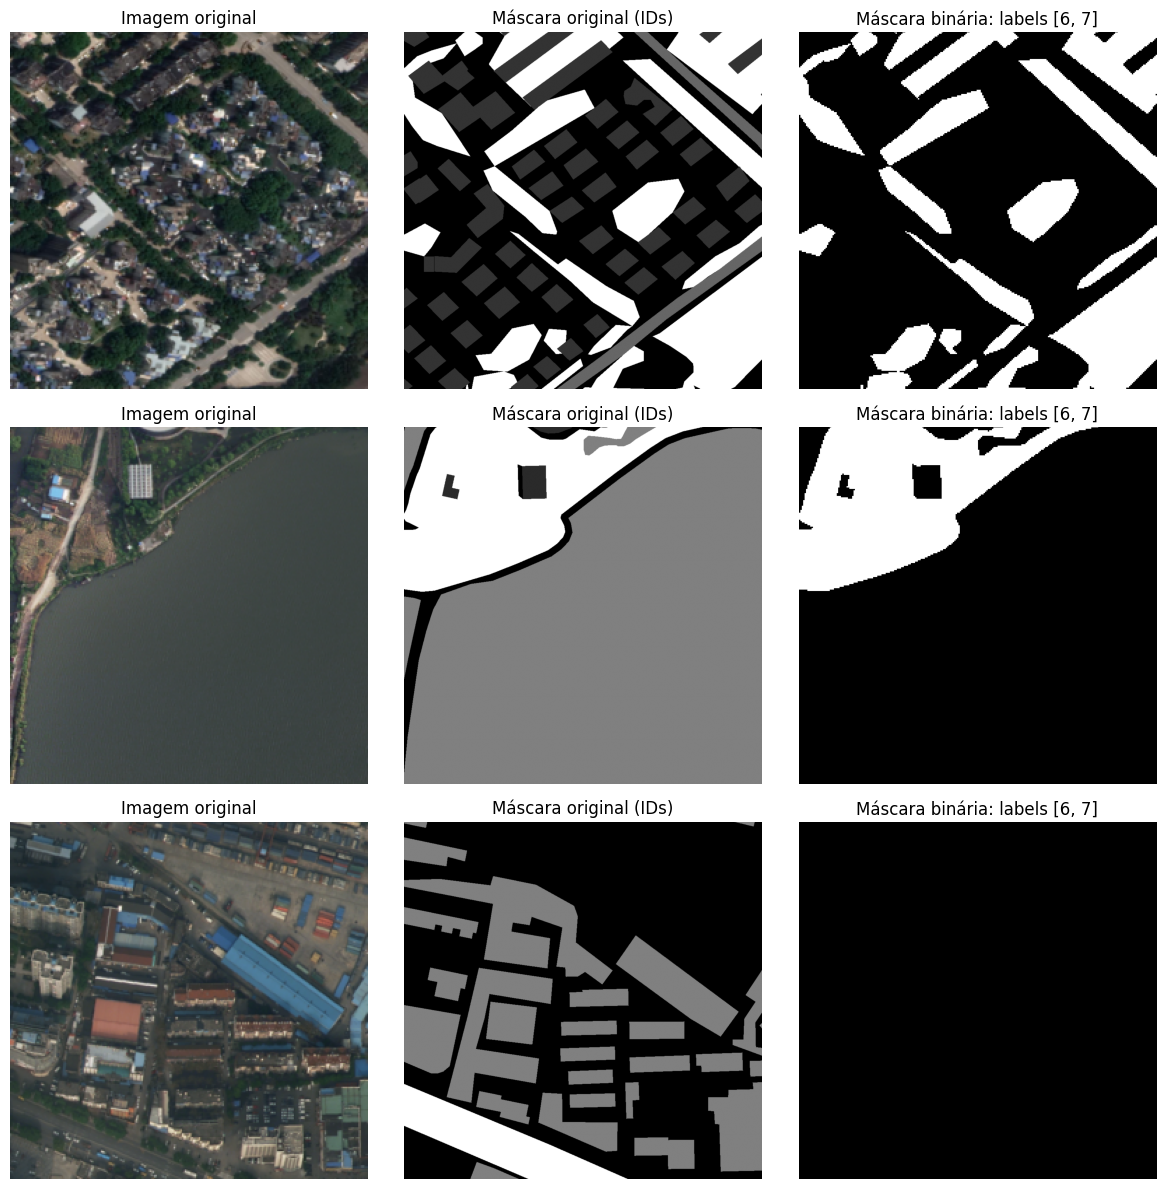

In [ ]:
def show_samples(samples, n=3):
    n = min(n, len(samples))
    fig, axes = plt.subplots(n, 3, figsize=(12, 4*n))
    if n == 1:
        axes = np.array([axes])
    ds = SatelliteSegmentationDataset(samples[:n], IMAGE_SIZE, augment=False)
    for i in range(n):
        image, binary_mask = ds[i]
        image_np = image.permute(1, 2, 0).numpy()
        mask_np = binary_mask[0].numpy()
        axes[i, 0].imshow(image_np)
        axes[i, 0].set_title("Imagem original")
        axes[i, 1].imshow(np.array(Image.open(samples[i][1]).convert("L")), cmap="gray")
        axes[i, 1].set_title("Máscara original (IDs)")
        axes[i, 2].imshow(mask_np, cmap="gray", vmin=0, vmax=1)
        axes[i, 2].set_title(f"Máscara binária: labels {GREEN_LABELS}")
        for ax in axes[i]:
            ax.axis("off")
    plt.tight_layout()
    plt.show()

show_samples(train_samples, n=3)


## 4. Modelo e métricas

Usamos U-Net padrão da SMP com um canal de saída (logits). A loss é `BCEWithLogitsLoss + DiceLoss`, útil quando a área verde ocupa uma fração pequena dos pixels.

In [ ]:
def build_model():
    return smp.Unet(
        encoder_name=ENCODER_NAME,
        encoder_weights=ENCODER_WEIGHTS,
        in_channels=3,
        classes=1,
        activation=None,
    ).to(DEVICE)

def segmentation_metrics(logits, masks, threshold=0.5):
    probs = torch.sigmoid(logits)
    preds = (probs >= threshold).float()
    tp = (preds * masks).sum().item()
    fp = (preds * (1 - masks)).sum().item()
    fn = ((1 - preds) * masks).sum().item()
    dice = (2*tp + 1e-8) / (2*tp + fp + fn + 1e-8)
    iou = (tp + 1e-8) / (tp + fp + fn + 1e-8)
    precision = (tp + 1e-8) / (tp + fp + 1e-8)
    recall = (tp + 1e-8) / (tp + fn + 1e-8)
    return {"dice": dice, "iou": iou, "precision": precision, "recall": recall}

class SegmentationLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = smp.losses.DiceLoss(mode="binary", from_logits=True)
    def forward(self, logits, masks):
        return self.bce(logits, masks) + self.dice(logits, masks)


## 5. Otimizadores e agendas

Comparações previstas no PDF: SGD com momento sem/com Nesterov, Adam, AdamW e Muon. Para U-Net, a maior parte dos pesos são kernels convolucionais 4-D; por isso, o Muon abaixo achata cada peso em uma matriz `(C_out, resto)` para ortogonalizar o gradiente com Newton–Schulz. Parâmetros 1-D (bias e normalizações) são atualizados com AdamW. Isso implementa a variante híbrida permitida pelo enunciado.

In [ ]:
def zeroth_power_newton_schulz(matrix, steps=5, eps=1e-7):
    # Aproxima a parte ortogonal U @ V.T da SVD usando Newton–Schulz.
    X = matrix
    if X.ndim != 2:
        raise ValueError("A ortogonalização espera matriz 2-D.")
    transposed = X.shape[0] > X.shape[1]
    if transposed:
        X = X.T
    X = X / (X.norm() + eps)
    a, b, c = 3.4445, -4.7750, 2.0315
    for _ in range(steps):
        A = X @ X.T
        X = a * X + (b * A + c * (A @ A)) @ X
    return X.T if transposed else X

class MuonMatrix(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-2, momentum=0.95, weight_decay=0.01, ns_steps=5):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay, ns_steps=ns_steps))
    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad(): loss = closure()
        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is None: continue
                g = p.grad
                if group["weight_decay"]:
                    g = g.add(p, alpha=group["weight_decay"])
                state = self.state[p]
                if "momentum_buffer" not in state:
                    state["momentum_buffer"] = g.clone()
                else:
                    state["momentum_buffer"].mul_(group["momentum"]).add_(g)
                mat = state["momentum_buffer"].reshape(p.shape[0], -1)
                update = zeroth_power_newton_schulz(mat, group["ns_steps"]).reshape_as(p)
                p.add_(update, alpha=-group["lr"])
        return loss

def build_optimizers(model, name, lr, adamw_lr=None):
    if name == "SGD":
        return [torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, nesterov=False, weight_decay=1e-4)]
    if name == "SGD_Nesterov":
        return [torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, nesterov=True, weight_decay=1e-4)]
    if name == "Adam":
        return [torch.optim.Adam(model.parameters(), lr=lr, weight_decay=0)]
    if name == "AdamW":
        return [torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)]

    if name == "Muon":
        # O Muon recebe matrizes e kernels das camadas internas.
        # A cabeça final de segmentação fica no AdamW.
        matrix_params = [
            p
            for n, p in model.named_parameters()
            if p.requires_grad
            and p.ndim >= 2
            and "segmentation_head" not in n
        ]

        matrix_ids = {id(p) for p in matrix_params}

        other_params = [
            p
            for p in model.parameters()
            if p.requires_grad and id(p) not in matrix_ids
        ]

        if not matrix_params:
            raise ValueError("Não há parâmetros elegíveis para o Muon.")

        return [
            MuonMatrix(
                matrix_params,
                lr=lr,
                momentum=0.95,
                weight_decay=0.01,
                ns_steps=5,
            ),
            torch.optim.AdamW(
                other_params,
                lr=(adamw_lr or BASELINE_LR),
                weight_decay=0.01,
            ),
        ]

    raise ValueError(f"Otimizador desconhecido: {name}")

def make_schedulers(optimizers, schedule_name, total_steps, warmup_fraction=0.05):
    schedulers = []
    for opt in optimizers:
        if schedule_name == "constant":
            sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda step: 1.0)
        elif schedule_name == "cosine":
            sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(1, total_steps), eta_min=0.0)
        elif schedule_name == "warmup_cosine":
            warmup_steps = max(1, int(total_steps * warmup_fraction))
            def scale(step, w=warmup_steps, total=max(2,total_steps)):
                if step < w: return float(step + 1) / w
                progress = min(1.0, (step - w) / max(1, total - w))
                return 0.5 * (1 + math.cos(math.pi * progress))
            sched = torch.optim.lr_scheduler.LambdaLR(opt, scale)
        elif schedule_name == "one_cycle":
            sched = torch.optim.lr_scheduler.OneCycleLR(
                opt, max_lr=opt.param_groups[0]["lr"], total_steps=max(1,total_steps),
                pct_start=0.1, anneal_strategy="cos"
            )
        elif schedule_name == "step":
            sched = torch.optim.lr_scheduler.StepLR(opt, step_size=max(1,total_steps//3), gamma=0.3)
        else:
            raise ValueError(f"Agenda desconhecida: {schedule_name}")
        schedulers.append(sched)
    return schedulers


## 6. Instrumentação: loss, gradiente, parâmetros, atualização e LR

O PDF pede logs a cada 10–50 passos, com norma global e por camada (início, meio e fim). Para manter os logs manejáveis, registramos a loss por lote e os demais sinais a cada `LOG_EVERY_STEPS`; a validação ocorre ao fim de cada época.

In [ ]:
def choose_probe_parameters(model):
    """
    Seleciona a primeira camada, uma intermediária e a última
    camada convolucional antes da cabeça de segmentação.
    """
    named = [
        (name, param)
        for name, param in model.named_parameters()
        if param.requires_grad
        and param.ndim >= 2
        and "weight" in name
        and "segmentation_head" not in name
    ]

    if len(named) < 3:
        raise ValueError(
            "Não há parâmetros matriciais suficientes "
            "para selecionar três camadas."
        )

    return {
        "primeira": named[0],
        "meio": named[len(named) // 2],
        "ultima": named[-1],
    }


def global_norm(params, use_grad=False):
    tensors = []
    for p in params:
        value = p.grad if use_grad else p
        if value is not None:
            tensors.append(value.detach().norm(2).pow(2))
    if not tensors: return 0.0
    return torch.stack(tensors).sum().sqrt().item()

def train_one_epoch(model, loader, loss_fn, optimizers, schedulers, epoch, log_rows,
                    global_step, probes, log_every=20, max_grad_norm=None):
    model.train()
    loss_sum = 0.0
    for batch_idx, (images, masks) in enumerate(loader):
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        for opt in optimizers: opt.zero_grad(set_to_none=True)
        logits = model(images)
        loss = loss_fn(logits, masks)
        loss.backward()

        grad_global = global_norm(model.parameters(), use_grad=True)  # antes de clipping
        grad_by_layer = {key: p.grad.detach().norm().item() if p.grad is not None else 0.0
                         for key, (name,p) in probes.items()}
        theta_global = global_norm(model.parameters(), use_grad=False)
        theta_by_layer = {key: p.detach().norm().item() for key, (name,p) in probes.items()}
        before = {key: p.detach().clone() for key, (name,p) in probes.items()}


        if max_grad_norm is not None:
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)

        # Guardar as taxas usadas neste passo, antes de atualizar as agendas.
        lrs_used = [opt.param_groups[0]["lr"] for opt in optimizers]

        for opt in optimizers:
            opt.step()

        for sched in schedulers:
            sched.step()

        loss_sum += loss.item()
        if global_step % log_every == 0 or batch_idx == len(loader)-1:

            row = {
                "step": global_step,
                "epoch": epoch,
                "batch": batch_idx,
                "loss_train_batch": loss.item(),
                "grad_norm_global": grad_global,
                "theta_norm_global": theta_global,
                "lr": lrs_used[0],
            }

            if len(optimizers) > 1:
              row["lr_aux"] = lrs_used[1]

            for key, (name,p) in probes.items():
                row[f"grad_{key}"] = grad_by_layer[key]
                row[f"theta_{key}"] = theta_by_layer[key]
                row[f"rho_{key}"] = ((p.detach()-before[key]).norm() / (before[key].norm()+1e-12)).item()
                row[f"layer_{key}"] = name
            log_rows.append(row)
        global_step += 1
    return loss_sum / max(1,len(loader)), global_step

@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    losses, all_tp, all_fp, all_fn = [], 0.0, 0.0, 0.0
    for images, masks in loader:
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        logits = model(images)
        losses.append(loss_fn(logits, masks).item())
        pred = (torch.sigmoid(logits) >= 0.5).float()
        all_tp += (pred*masks).sum().item()
        all_fp += (pred*(1-masks)).sum().item()
        all_fn += ((1-pred)*masks).sum().item()
    dice = (2*all_tp+1e-8)/(2*all_tp+all_fp+all_fn+1e-8)
    iou = (all_tp+1e-8)/(all_tp+all_fp+all_fn+1e-8)
    return {"val_loss": float(np.mean(losses)), "val_dice": dice, "val_iou": iou}


In [ ]:

# Verifica a seleção sem iniciar o treinamento
model_teste = build_model()

probe_parameters = choose_probe_parameters(model_teste)

for label, (name, parameter) in probe_parameters.items():
    print(
        f"{label:8s} | "
        f"camada: {name} | "
        f"formato: {tuple(parameter.shape)}"
    )

del model_teste


primeira | camada: encoder.conv1.weight | formato: (64, 3, 7, 7)
meio     | camada: encoder.layer3.3.conv1.weight | formato: (256, 256, 3, 3)
ultima   | camada: decoder.blocks.4.conv2.0.weight | formato: (16, 16, 3, 3)


## 7. Execução de um experimento

A seleção do melhor checkpoint é feita pela métrica de validação (Dice). O conjunto de teste fica reservado para a confirmação final; não o usamos para escolher hiperparâmetros.

In [ ]:
def run_experiment(optimizer_name, lr, schedule_name, seed=42, epochs=SWEEP_EPOCHS,
                   stage="sweep", adamw_lr=None, evaluate_test=False):
    set_seed(seed)
    train_ds = SatelliteSegmentationDataset(train_samples, IMAGE_SIZE, augment=True)
    val_ds = SatelliteSegmentationDataset(val_samples, IMAGE_SIZE, augment=False)
    test_ds = SatelliteSegmentationDataset(test_samples, IMAGE_SIZE, augment=False)
    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                              pin_memory=(DEVICE.type=="cuda"), generator=generator)
    val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, num_workers=NUM_WORKERS)
    test_loader = DataLoader(test_ds, batch_size=1, shuffle=False, num_workers=NUM_WORKERS)

    model = build_model()
    loss_fn = SegmentationLoss()
    optimizers = build_optimizers(model, optimizer_name, lr, adamw_lr=adamw_lr)
    total_steps = max(1, epochs * len(train_loader))
    schedulers = make_schedulers(optimizers, schedule_name, total_steps)
    probes = choose_probe_parameters(model)
    log_rows, epoch_rows = [], []
    best_dice, best_state = -1.0, None
    global_step, diverged = 0, False
    start = time.time()

    print(f"\n[{stage}] {optimizer_name} | lr={lr:g} | agenda={schedule_name} | seed={seed} | épocas={epochs}")
    for epoch in range(1, epochs+1):
        train_loss, global_step = train_one_epoch(
            model, train_loader, loss_fn, optimizers, schedulers, epoch, log_rows,
            global_step, probes, LOG_EVERY_STEPS, MAX_GRAD_NORM
        )
        val = evaluate(model, val_loader, loss_fn)
        epoch_row = {"epoch":epoch, "train_loss":train_loss, **val}
        epoch_rows.append(epoch_row)
        print(f"Época {epoch:02d}/{epochs} | train_loss={train_loss:.4f} | "
              f"val_loss={val['val_loss']:.4f} | Dice={val['val_dice']:.4f} | IoU={val['val_iou']:.4f}")
        if not np.isfinite(train_loss) or not np.isfinite(val["val_loss"]):
            diverged = True
            break
        if val["val_dice"] > best_dice:
            best_dice = val["val_dice"]
            best_state = {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}

    elapsed = time.time() - start
    result = {
        "stage":stage, "optimizer":optimizer_name, "lr":lr, "schedule":schedule_name,
        "seed":seed, "epochs_requested":epochs, "epochs_completed":len(epoch_rows),
        "best_val_dice":best_dice, "last_val_loss":epoch_rows[-1]["val_loss"] if epoch_rows else np.nan,
        "last_val_iou":epoch_rows[-1]["val_iou"] if epoch_rows else np.nan,
        "diverged":diverged, "seconds":elapsed, "adamw_lr":adamw_lr,
    }
    run_id = f"{stage}_{optimizer_name}_lr{lr:g}_{schedule_name}_seed{seed}".replace(".","p")
    run_dir = os.path.join(OUTPUT_DIR, "logs")
    os.makedirs(run_dir, exist_ok=True)
    pd.DataFrame(log_rows).to_csv(os.path.join(run_dir, f"{run_id}_signals.csv"), index=False)
    pd.DataFrame(epoch_rows).to_csv(os.path.join(run_dir, f"{run_id}_epochs.csv"), index=False)
    if best_state is not None:
        model.load_state_dict(best_state)
        torch.save(best_state, os.path.join(run_dir, f"{run_id}_best.pt"))
    if evaluate_test and best_state is not None:
        result.update({"test_"+k:v for k,v in evaluate(model, test_loader, loss_fn).items()})
    del model, optimizers, schedulers
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return result


## 8. Teste rápido

Rode antes de iniciar dezenas de execuções. Se o dataset for grande, o teste rápido ajuda a verificar se o carregamento, a loss e os logs funcionam.

In [ ]:
# TESTE RÁPIDO: 1 época, não conta como resultado oficial.
teste_rapido = run_experiment("AdamW", 1e-4, "warmup_cosine", seed=42, epochs=1, stage="smoke_test")
pd.DataFrame([teste_rapido])



[smoke_test] AdamW | lr=0.0001 | agenda=warmup_cosine | seed=42 | épocas=1
Época 01/1 | train_loss=1.2670 | val_loss=1.0910 | Dice=0.5763 | IoU=0.4048


,stage,optimizer,lr,schedule,seed,epochs_requested,epochs_completed,best_val_dice,last_val_loss,last_val_iou,diverged,seconds,adamw_lr
0,smoke_test,AdamW,0.0001,warmup_cosine,42,1,1,0.576285,1.09105,0.404776,False,672.642045,None


## 9. Etapa 1 — Baseline

O PDF pede a receita baseline em três sementes. Aqui a baseline é AdamW + warmup/cosseno; se vocês já tiverem uma receita anterior do projeto, alterem `BASELINE_OPTIMIZER`, `BASELINE_LR` e `BASELINE_SCHEDULE` para representá-la.

In [ ]:
baseline_results = []
for seed in SEEDS:
    baseline_results.append(run_experiment(
        BASELINE_OPTIMIZER, BASELINE_LR, BASELINE_SCHEDULE,
        seed=seed, epochs=BASELINE_EPOCHS, stage="baseline"
    ))
df_baseline = pd.DataFrame(baseline_results)
display(df_baseline)
df_baseline.to_csv(os.path.join(OUTPUT_DIR, "baseline.csv"), index=False)



[baseline] AdamW | lr=0.0001 | agenda=warmup_cosine | seed=42 | épocas=15
Época 01/15 | train_loss=1.3940 | val_loss=1.3328 | Dice=0.4460 | IoU=0.2870
Época 02/15 | train_loss=1.0391 | val_loss=0.9525 | Dice=0.6037 | IoU=0.4324
Época 03/15 | train_loss=0.9461 | val_loss=1.0401 | Dice=0.5372 | IoU=0.3672
Época 04/15 | train_loss=0.8803 | val_loss=1.0698 | Dice=0.6064 | IoU=0.4352
Época 05/15 | train_loss=0.8470 | val_loss=0.9295 | Dice=0.5507 | IoU=0.3800
Época 06/15 | train_loss=0.7905 | val_loss=0.8427 | Dice=0.6867 | IoU=0.5229
Época 07/15 | train_loss=0.7645 | val_loss=1.0022 | Dice=0.6178 | IoU=0.4470
Época 08/15 | train_loss=0.7481 | val_loss=0.8010 | Dice=0.6932 | IoU=0.5304
Época 09/15 | train_loss=0.7323 | val_loss=0.7926 | Dice=0.7112 | IoU=0.5519
Época 10/15 | train_loss=0.7293 | val_loss=0.7946 | Dice=0.7104 | IoU=0.5509
Época 11/15 | train_loss=0.6979 | val_loss=0.8100 | Dice=0.7132 | IoU=0.5542
Época 12/15 | train_loss=0.7083 | val_loss=0.7822 | Dice=0.7184 | IoU=0.5605
É

,stage,optimizer,lr,schedule,seed,epochs_requested,epochs_completed,best_val_dice,last_val_loss,last_val_iou,diverged,seconds,adamw_lr
0,baseline,AdamW,0.0001,warmup_cosine,42,15,15,0.732832,0.757461,0.578323,False,1518.248952,None
1,baseline,AdamW,0.0001,warmup_cosine,94,15,15,0.726118,0.775128,0.570004,False,1521.316199,None
2,baseline,AdamW,0.0001,warmup_cosine,168,15,15,0.721180,0.771308,0.562892,False,1527.396051,None


## 10. Etapa 2 — Varredura de learning rate

Mínimo de cinco valores em grade logarítmica por otimizador, todos usando warmup + cosseno e uma semente, conforme o protocolo. A grade é diferente por otimizador para não comparar taxas que favorecem artificialmente apenas uma família. Para Muon, a taxa se refere às matrizes; o AdamW auxiliar usa `BASELINE_LR` inicialmente. Se o melhor LR cair na borda da grade, amplie-a.

In [ ]:
lr_results = []
for opt_name, lr_values in LR_GRIDS.items():
    for lr in lr_values:
        try:
            lr_results.append(run_experiment(
                opt_name, lr, "warmup_cosine", seed=SEEDS[0],
                epochs=SWEEP_EPOCHS, stage="lr_sweep",
                adamw_lr=BASELINE_LR if opt_name=="Muon" else None
            ))
        except Exception as exc:
            print(f"Falha registrada: {opt_name}, lr={lr:g}: {exc}")
            lr_results.append({
                "stage":"lr_sweep", "optimizer":opt_name, "lr":lr,
                "schedule":"warmup_cosine", "seed":SEEDS[0],
                "best_val_dice":np.nan, "diverged":True, "error":repr(exc)
            })
df_lr = pd.DataFrame(lr_results)
df_lr.to_csv(os.path.join(OUTPUT_DIR, "lr_sweep.csv"), index=False)
display(df_lr.sort_values("best_val_dice", ascending=False))



[lr_sweep] SGD | lr=0.001 | agenda=warmup_cosine | seed=42 | épocas=5
Época 01/5 | train_loss=1.2036 | val_loss=1.1503 | Dice=0.4713 | IoU=0.3083
Época 02/5 | train_loss=0.9474 | val_loss=1.0243 | Dice=0.5632 | IoU=0.3919
Época 03/5 | train_loss=0.9153 | val_loss=0.9453 | Dice=0.6067 | IoU=0.4354
Época 04/5 | train_loss=0.8841 | val_loss=0.9042 | Dice=0.6219 | IoU=0.4512
Época 05/5 | train_loss=0.8859 | val_loss=0.8949 | Dice=0.6287 | IoU=0.4584

[lr_sweep] SGD | lr=0.003 | agenda=warmup_cosine | seed=42 | épocas=5
Época 01/5 | train_loss=1.1109 | val_loss=0.9833 | Dice=0.5182 | IoU=0.3498
Época 02/5 | train_loss=0.9055 | val_loss=1.0481 | Dice=0.5463 | IoU=0.3758
Época 03/5 | train_loss=0.8714 | val_loss=0.9721 | Dice=0.5918 | IoU=0.4202
Época 04/5 | train_loss=0.8274 | val_loss=0.8605 | Dice=0.6637 | IoU=0.4966
Época 05/5 | train_loss=0.8224 | val_loss=0.8478 | Dice=0.6662 | IoU=0.4995

[lr_sweep] SGD | lr=0.01 | agenda=warmup_cosine | seed=42 | épocas=5
Época 01/5 | train_loss=1.06

,stage,optimizer,lr,schedule,seed,epochs_requested,epochs_completed,best_val_dice,last_val_loss,last_val_iou,diverged,seconds,adamw_lr
21,lr_sweep,Muon,0.00300,warmup_cosine,42,5,5,0.707889,0.837668,0.547855,False,489.239804,0.0001
18,lr_sweep,AdamW,0.00030,warmup_cosine,42,5,5,0.693222,0.814536,0.530482,False,460.596524,NaN
13,lr_sweep,Adam,0.00030,warmup_cosine,42,5,5,0.683484,0.825052,0.519162,False,467.783108,NaN
22,lr_sweep,Muon,0.01000,warmup_cosine,42,5,5,0.682158,0.860631,0.517633,False,493.353549,0.0001
20,lr_sweep,Muon,0.00100,warmup_cosine,42,5,5,0.679383,0.869957,0.514443,False,491.879996,0.0001
17,lr_sweep,AdamW,0.00010,warmup_cosine,42,5,5,0.676807,0.886535,0.511495,False,465.988583,NaN
7,lr_sweep,SGD_Nesterov,0.01000,warmup_cosine,42,5,5,0.675497,0.840761,0.510000,False,486.813956,NaN
2,lr_sweep,SGD,0.01000,warmup_cosine,42,5,5,0.675065,0.830690,0.509508,False,478.020284,NaN
12,lr_sweep,Adam,0.00010,warmup_cosine,42,5,5,0.674865,0.884384,0.509280,False,483.475052,NaN
3,lr_sweep,SGD,0.03000,warmup_cosine,42,5,5,0.673250,0.835963,0.507443,False,480.682764,NaN


## 11. Etapa 3 — Comparação de agendas

Compare as quatro agendas pedidas: constante (controle), cosseno, warmup + cosseno e uma quarta (OneCycle). Usamos os dois melhores otimizadores da varredura e garantimos que Muon também entre na comparação.

In [ ]:
valid_lr = df_lr.dropna(subset=["best_val_dice"]).copy()
best_by_optimizer = (valid_lr.sort_values("best_val_dice", ascending=False)
                     .groupby("optimizer", as_index=False).first()
                     .sort_values("best_val_dice", ascending=False))
chosen_optimizers = best_by_optimizer["optimizer"].head(2).tolist()
if "Muon" not in chosen_optimizers:
    chosen_optimizers.append("Muon")
print("Otimizadores para comparar agendas:", chosen_optimizers)

best_lr = {row["optimizer"]: float(row["lr"]) for _,row in best_by_optimizer.iterrows()}
SCHEDULES = ["constant", "cosine", "warmup_cosine", "one_cycle"]
schedule_results = []
for opt_name in chosen_optimizers:
    lr = best_lr.get(opt_name, LR_GRIDS[opt_name][2])
    for schedule_name in SCHEDULES:
        try:
            schedule_results.append(run_experiment(
                opt_name, lr, schedule_name, seed=SEEDS[0],
                epochs=SWEEP_EPOCHS, stage="schedule_sweep",
                adamw_lr=BASELINE_LR if opt_name=="Muon" else None
            ))
        except Exception as exc:
            print(f"Falha registrada: {opt_name}, {schedule_name}: {exc}")
            schedule_results.append({
                "stage":"schedule_sweep", "optimizer":opt_name, "lr":lr,
                "schedule":schedule_name, "seed":SEEDS[0],
                "best_val_dice":np.nan, "diverged":True, "error":repr(exc)
            })
df_schedules = pd.DataFrame(schedule_results)
df_schedules.to_csv(os.path.join(OUTPUT_DIR, "schedule_sweep.csv"), index=False)
display(df_schedules.sort_values("best_val_dice", ascending=False))


Otimizadores para comparar agendas: ['Muon', 'AdamW']

[schedule_sweep] Muon | lr=0.003 | agenda=constant | seed=42 | épocas=5
Época 01/5 | train_loss=1.2173 | val_loss=1.5165 | Dice=0.4232 | IoU=0.2684
Época 02/5 | train_loss=0.9511 | val_loss=1.4654 | Dice=0.4565 | IoU=0.2958
Época 03/5 | train_loss=0.8707 | val_loss=0.9014 | Dice=0.6203 | IoU=0.4496
Época 04/5 | train_loss=0.8306 | val_loss=1.2816 | Dice=0.4917 | IoU=0.3260
Época 05/5 | train_loss=0.8220 | val_loss=0.8780 | Dice=0.6086 | IoU=0.4374

[schedule_sweep] Muon | lr=0.003 | agenda=cosine | seed=42 | épocas=5
Época 01/5 | train_loss=1.2178 | val_loss=1.5623 | Dice=0.4042 | IoU=0.2533
Época 02/5 | train_loss=0.9519 | val_loss=0.9042 | Dice=0.6121 | IoU=0.4410
Época 03/5 | train_loss=0.8725 | val_loss=0.9068 | Dice=0.6507 | IoU=0.4822
Época 04/5 | train_loss=0.8095 | val_loss=0.8389 | Dice=0.6996 | IoU=0.5380


## 12. Etapa 4 — Confirmação com três sementes

Selecionamos as três melhores combinações por Dice de validação considerando a varredura de LR e de agendas, depois rodamos cada uma nas três sementes. A comparação final deve considerar média **e desvio-padrão**, não apenas o melhor valor isolado.

In [ ]:
candidates_lr = valid_lr[["optimizer","lr","schedule","best_val_dice"]].copy()
candidates_sched = df_schedules.dropna(subset=["best_val_dice"])[["optimizer","lr","schedule","best_val_dice"]].copy()
candidates = pd.concat([candidates_lr, candidates_sched], ignore_index=True)
candidates = candidates.sort_values("best_val_dice", ascending=False).drop_duplicates(
    subset=["optimizer","lr","schedule"]
).head(3)
display(candidates)

confirmation_results = []
for _, cfg in candidates.iterrows():
    for seed in SEEDS:
        confirmation_results.append(run_experiment(
            str(cfg["optimizer"]), float(cfg["lr"]), str(cfg["schedule"]),
            seed=seed, epochs=FINAL_EPOCHS, stage="confirmation",
            adamw_lr=BASELINE_LR if cfg["optimizer"]=="Muon" else None,
            evaluate_test=False
        ))
df_confirmation = pd.DataFrame(confirmation_results)
df_confirmation.to_csv(os.path.join(OUTPUT_DIR, "confirmation.csv"), index=False)
summary_confirmation = (df_confirmation.groupby(["optimizer","lr","schedule"])
                        .agg(dice_mean=("best_val_dice","mean"),
                             dice_std=("best_val_dice","std"),
                             seconds_mean=("seconds","mean"),
                             diverged_runs=("diverged","sum"))
                        .reset_index().sort_values("dice_mean", ascending=False))
display(summary_confirmation)


## 13. Avaliação final no teste

Só depois de escolher a configuração pela validação, rode esta célula uma vez. O teste é reservado para a estimativa final.

In [ ]:
# Escolha a melhor configuração confirmada pela média no conjunto de validação.
winner = summary_confirmation.iloc[0]
print("Configuração escolhida:", winner.to_dict())

# Para a avaliação de teste, treinamos uma execução com a semente principal.
# O resultado é final para esta semente; idealmente reporte também a média das três sementes
# se a entrega exigir métricas de teste por semente.
final_test_result = run_experiment(
    str(winner["optimizer"]), float(winner["lr"]), str(winner["schedule"]),
    seed=SEEDS[0], epochs=FINAL_EPOCHS, stage="final_test",
    adamw_lr=BASELINE_LR if winner["optimizer"]=="Muon" else None,
    evaluate_test=True
)
pd.DataFrame([final_test_result]).to_csv(os.path.join(OUTPUT_DIR, "final_test.csv"), index=False)
display(pd.DataFrame([final_test_result]))


## 14. Consolidando os experimentos

In [ ]:
def consolidar_experimentos():
    """Reúne os CSVs das etapas em um único arquivo."""
    arquivos = [
        "baseline.csv",
        "lr_sweep.csv",
        "schedule_sweep.csv",
        "confirmation.csv",
        "final_test.csv",
    ]

    tabelas = []

    for arquivo in arquivos:
        caminho = os.path.join(OUTPUT_DIR, arquivo)

        if not os.path.isfile(caminho):
            continue

        df = pd.read_csv(caminho)

        if df.empty:
            continue

        # Identifica a etapa de origem de cada resultado.
        df["arquivo_origem"] = arquivo
        tabelas.append(df)

    destino = os.path.join(OUTPUT_DIR, "experimentos.csv")

    if tabelas:
        consolidado = pd.concat(tabelas, ignore_index=True, sort=False)
    else:
        consolidado = pd.DataFrame()

    consolidado.to_csv(destino, index=False)

    print(f"Arquivo consolidado salvo em: {destino}")
    print(f"Total de registros: {len(consolidado)}")
    print(f"Arquivos de origem encontrados: {len(tabelas)}")

    return consolidado


## 15. Análise visual dos resultados salvos

Esta seção funciona após montar o Drive, sem executar instalação, configuração do modelo ou treinamento.

**O que será gerado:**

  - 01_varredura_lr.png      - uma linha por otimizador, melhor LR marcado com estrela
  - 02_agendas.png           - Dice por agenda, uma linha por otimizador
  - 03_confirmacao.png       - média e sementes de cada configuração confirmada
  - 04_sinais_agendas.png    - loss, Dice, LR, gradiente, parâmetros e atualização (Etapa 3)
  - 05_sinais_baseline_vs_melhor.png - mesma coisa: baseline x melhor da confirmação.


In [ ]:
def plot_signals(csv_path, title=None):
    df = pd.read_csv(csv_path)
    if df.empty:
        print("Log vazio:", csv_path); return
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    axes[0,0].plot(df["step"], df["loss_train_batch"])
    axes[0,0].set_title("Loss de treino por lote"); axes[0,0].set_xlabel("Passo")
    axes[0,1].plot(df["step"], df["grad_norm_global"], label="Global")
    for c in ["grad_primeira","grad_meio","grad_ultima"]:
        if c in df: axes[0,1].plot(df["step"], df[c], label=c)
    axes[0,1].set_yscale("symlog"); axes[0,1].set_title("Norma do gradiente"); axes[0,1].set_xlabel("Passo"); axes[0,1].legend()
    axes[1,0].plot(df["step"], df["theta_norm_global"], label="Global")
    for c in ["theta_primeira","theta_meio","theta_ultima"]:
        if c in df: axes[1,0].plot(df["step"], df[c], label=c)
    axes[1,0].set_title("Norma dos parâmetros"); axes[1,0].set_xlabel("Passo"); axes[1,0].legend()
    axes[1,1].plot(df["step"], df["lr"])
    axes[1,1].set_title("Learning rate"); axes[1,1].set_xlabel("Passo")
    fig.suptitle(title or Path(csv_path).stem)
    plt.tight_layout(); plt.show()


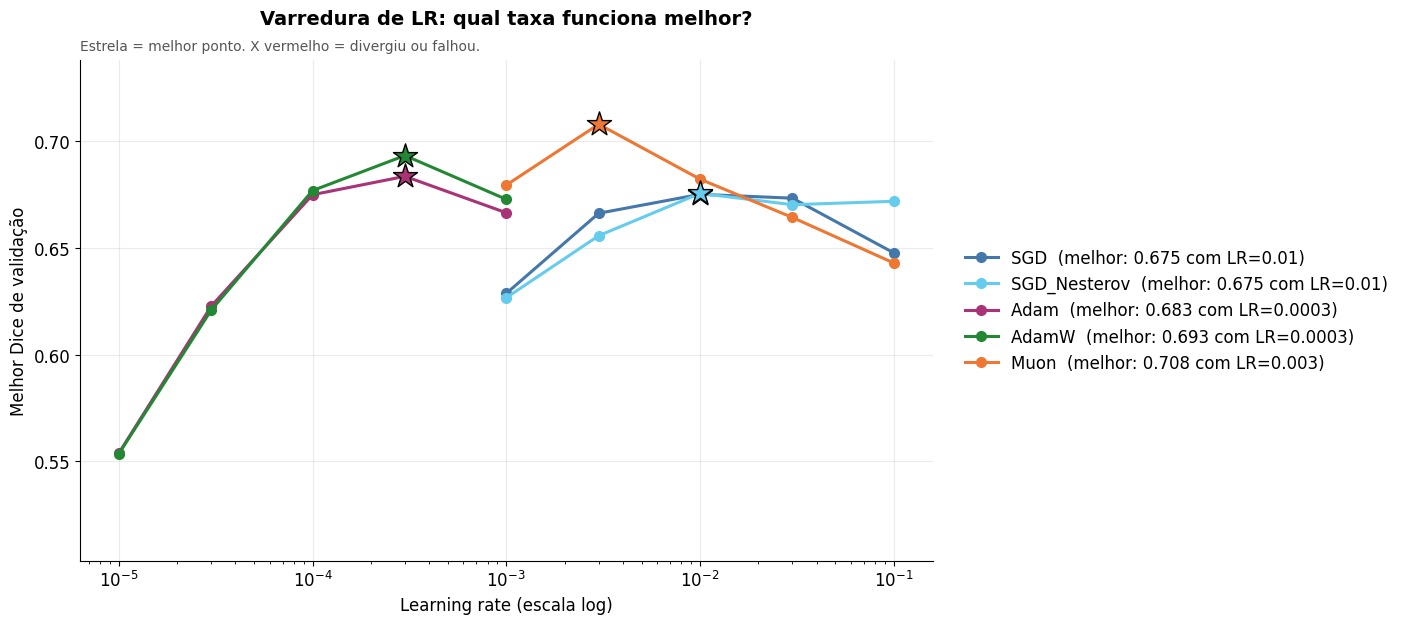

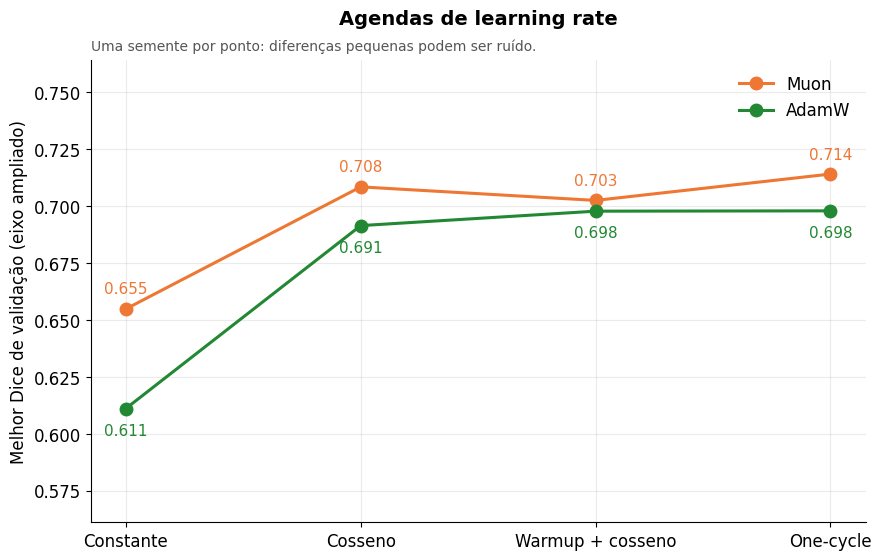

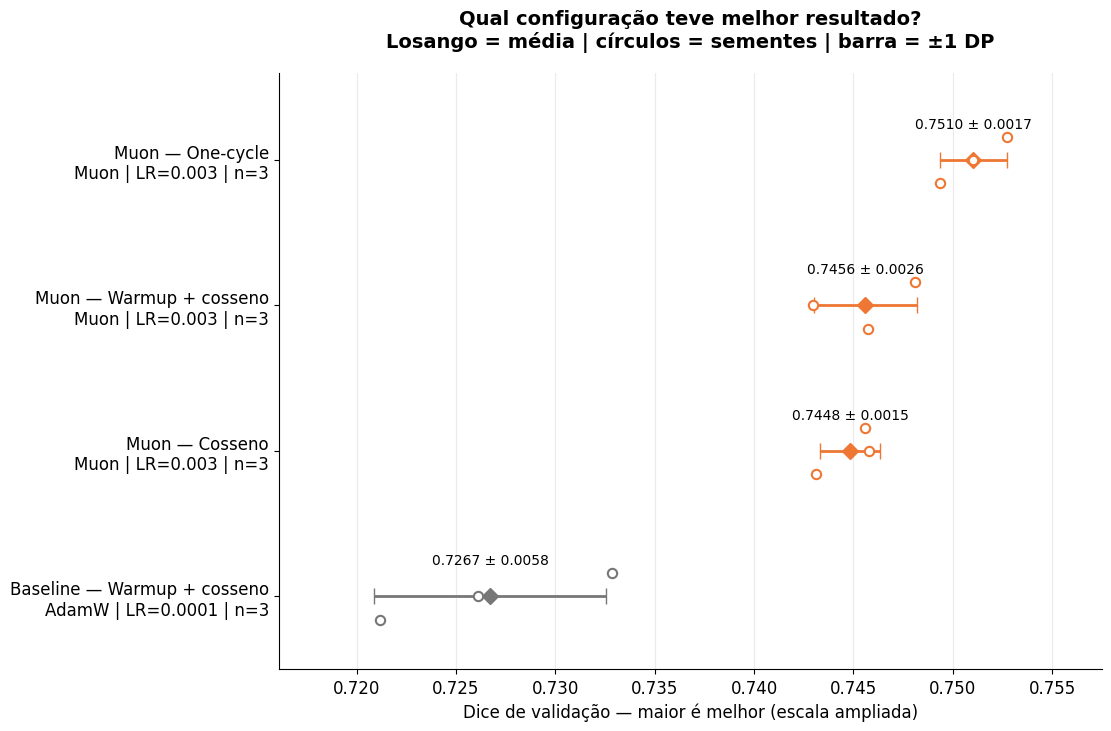

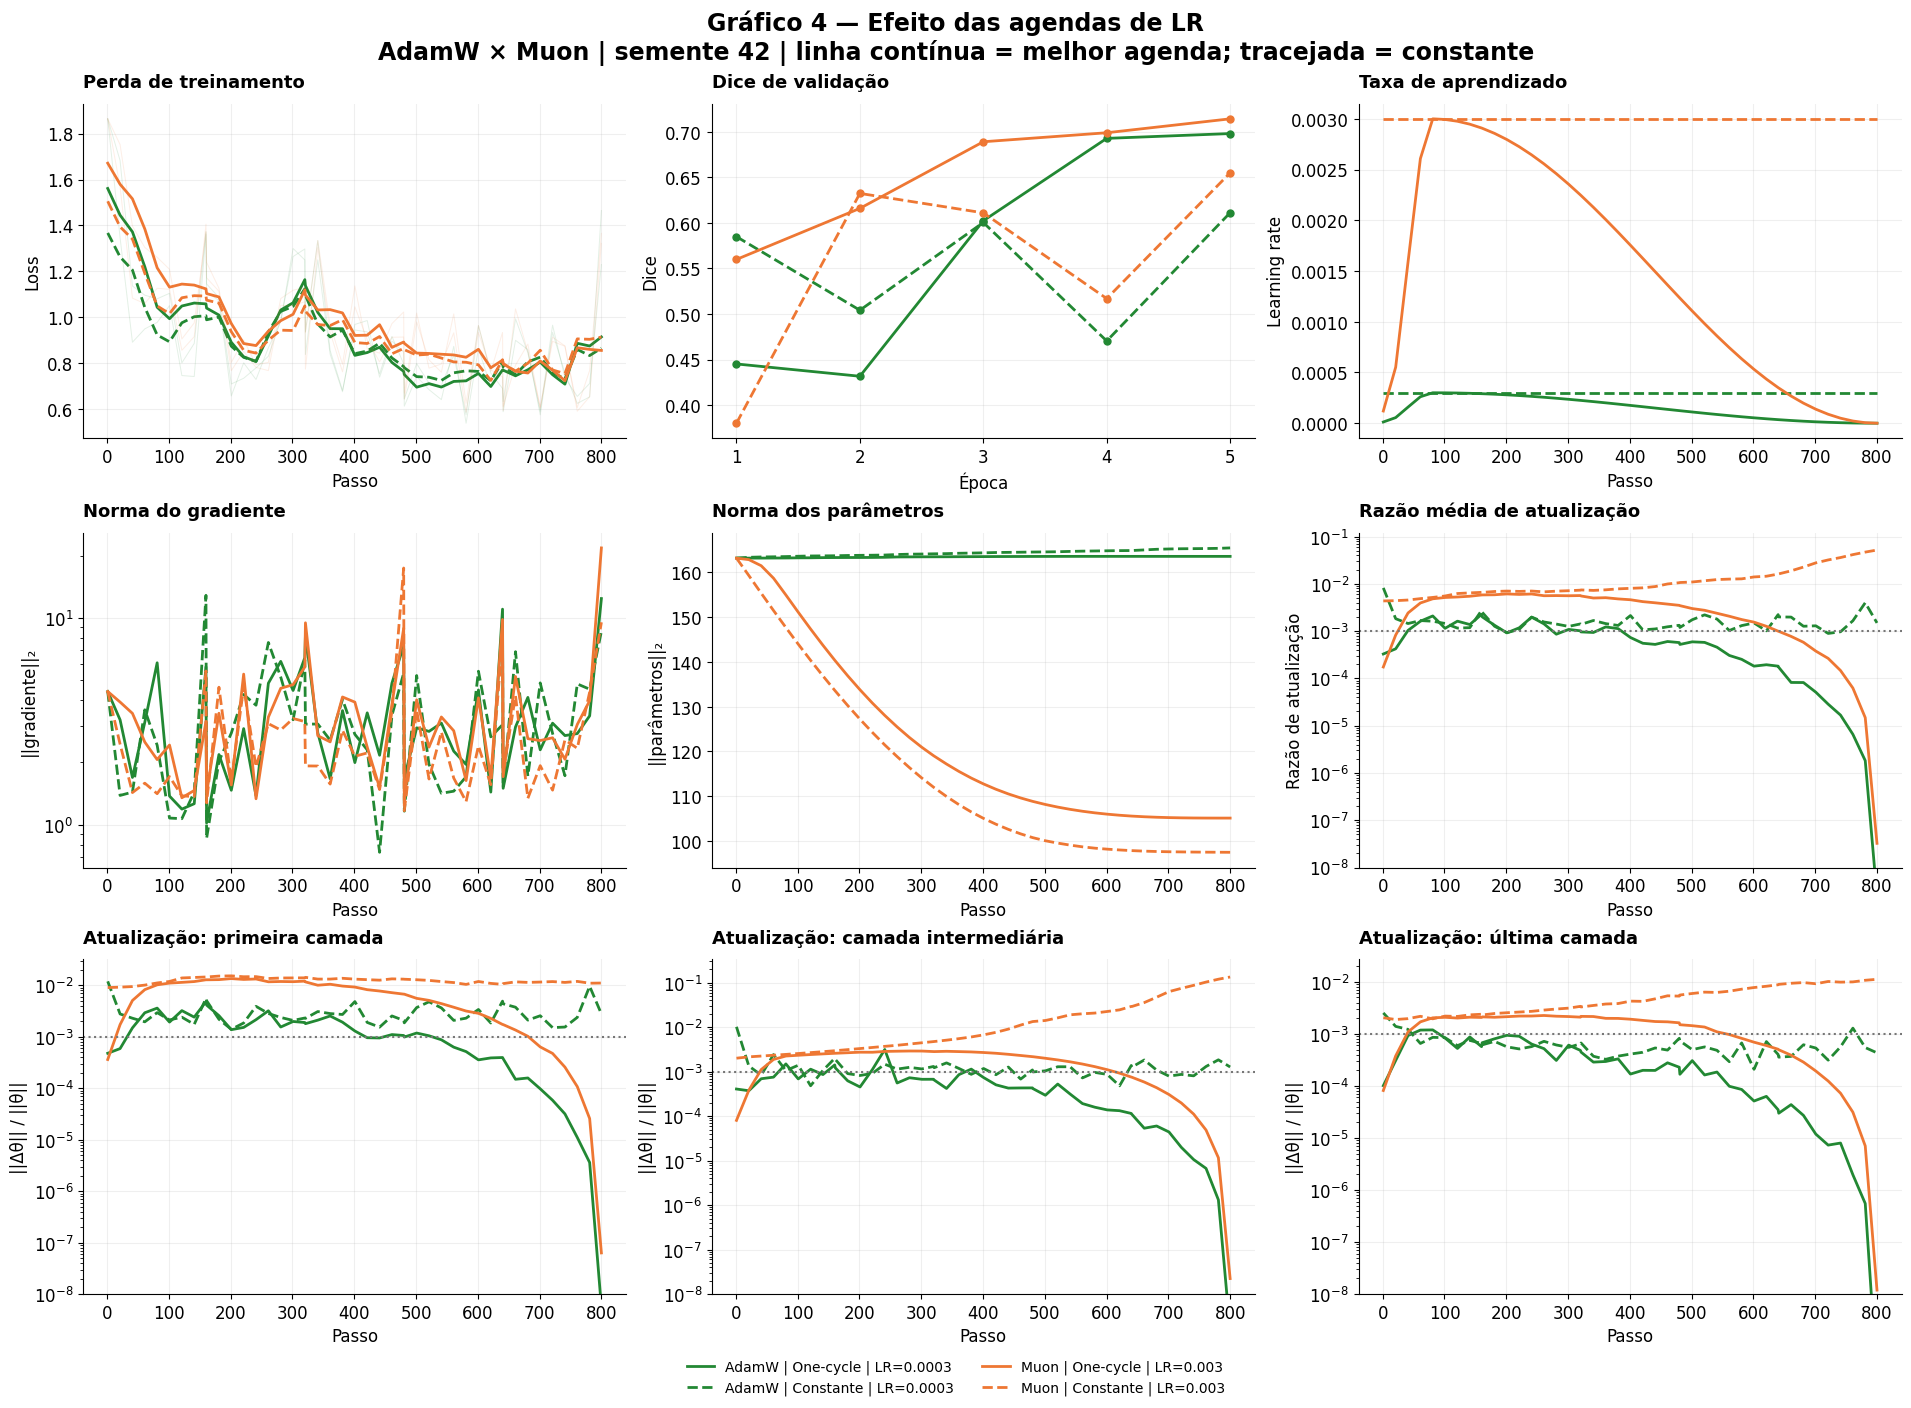

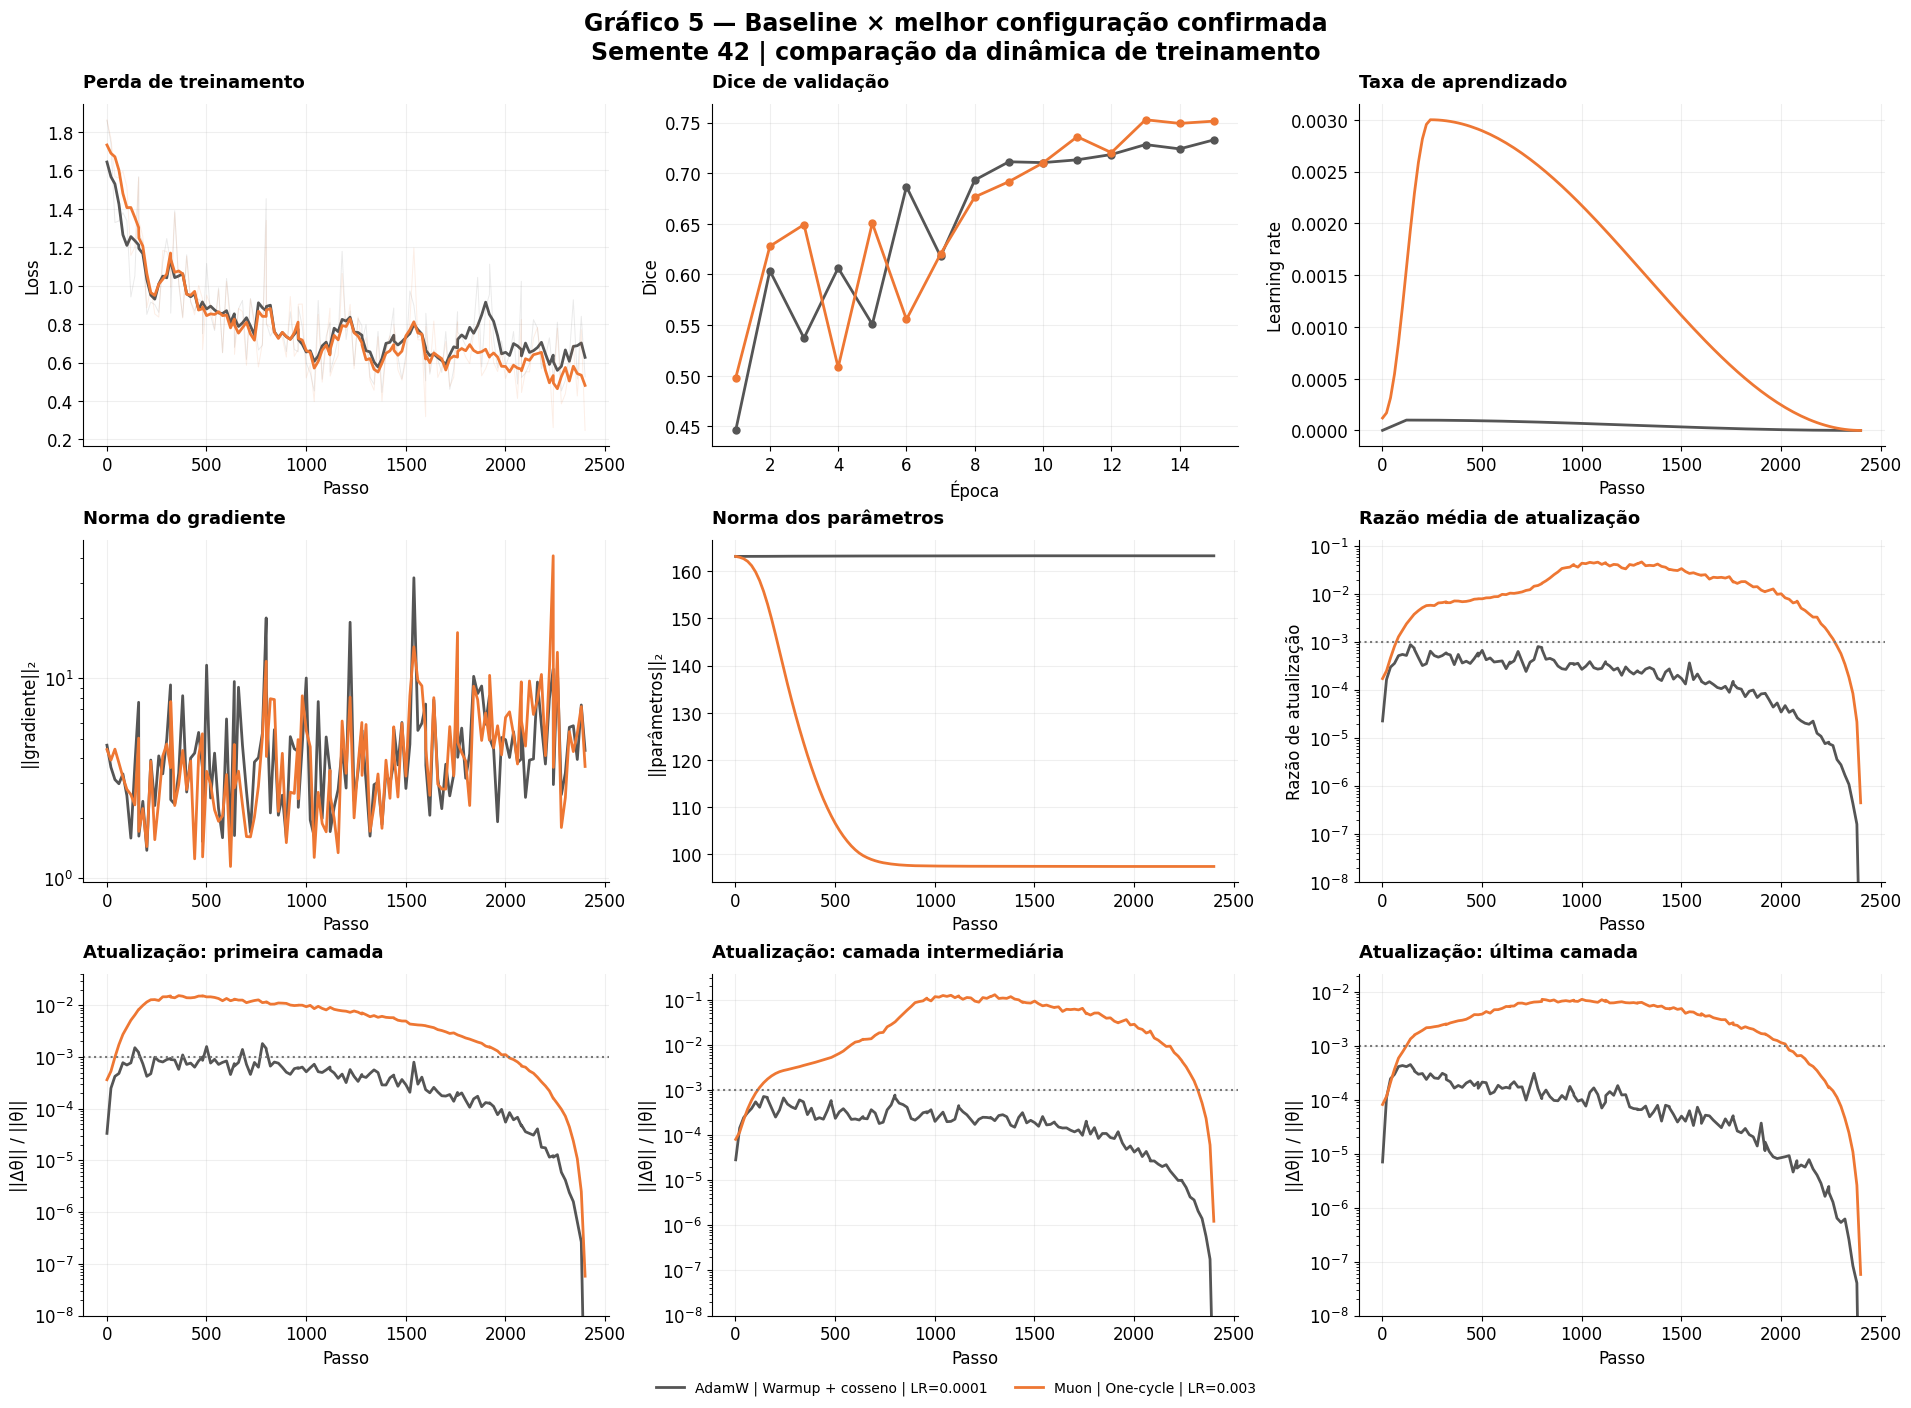

Gráficos salvos em: /content/drive/MyDrive/desafio3_resultados/graficos_simples


In [ ]:
OUTPUT_DIR = globals().get("OUTPUT_DIR", "desafio3_resultados")
MOSTRAR = globals().get("MOSTRAR_FIGURAS", True)
SEMENTE = 42      # semente usada nos painéis de sinais
JANELA = 5        # suavização da loss (em registros)

ROOT = Path(OUTPUT_DIR)
LOG_DIR = ROOT / "logs"
PLOTS = ROOT / "graficos_simples"
PLOTS.mkdir(parents=True, exist_ok=True)

COR = {"SGD": "#4477AA", "SGD_Nesterov": "#66CCEE", "Adam": "#AA3377",
       "AdamW": "#228833", "Muon": "#EE7733"}
AGENDA = {"constant": "Constante", "cosine": "Cosseno",
          "warmup_cosine": "Warmup + cosseno", "one_cycle": "One-cycle"}

plt.rcParams.update({
    "font.size": 12, "axes.titlesize": 14, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
    "figure.facecolor": "white", "savefig.facecolor": "white",
})


# ---------------------------------------------------------------- dados
def ler(path):
    try:
        return pd.read_csv(path)
    except (FileNotFoundError, pd.errors.EmptyDataError):
        return pd.DataFrame()


partes = []
for etapa in ["baseline", "lr_sweep", "schedule_sweep", "confirmation", "final_test"]:
    d = ler(ROOT / f"{etapa}.csv")
    if not d.empty:
        partes.append(d.assign(stage=etapa))
if not partes:
    raise ValueError(f"Nenhum CSV encontrado em {ROOT}. Confira OUTPUT_DIR.")

exp = pd.concat(partes, ignore_index=True)
exp["diverged"] = exp["diverged"].astype(str).str.lower().isin(["true", "1", "1.0"])
for c in ["lr", "seed", "best_val_dice"]:
    exp[c] = pd.to_numeric(exp[c], errors="coerce")


def validos(d):
    return d[(~d["diverged"]) & d["best_val_dice"].notna()]


def run_id(r):
    return (f"{r['stage']}_{r['optimizer']}_lr{float(r['lr']):g}_"
            f"{r['schedule']}_seed{int(r['seed'])}").replace(".", "p")


def rotulo(r):
    return f"{r['optimizer']} | {AGENDA.get(r['schedule'], r['schedule'])} | LR={float(r['lr']):g}"


def nota(ax, texto):
    ax.set_title(ax.get_title(), pad=26)
    ax.text(0, 1.015, texto, transform=ax.transAxes, fontsize=10, color="#555555", va="bottom")


def salvar(fig, nome):
    fig.savefig(PLOTS / f"{nome}.png", dpi=150, bbox_inches="tight")
    if MOSTRAR:
        plt.show()
    plt.close(fig)


# ------------------------------------------------- 1. varredura de LR
def fig_lr():
    d = exp[exp["stage"] == "lr_sweep"]
    if d.empty:
        return
    fig, ax = plt.subplots(figsize=(11, 6.5))
    v_all = validos(d)
    ymin = v_all["best_val_dice"].min() - 0.05 if len(v_all) else 0
    ymax = v_all["best_val_dice"].max() + 0.03 if len(v_all) else 1
    for opt, g in d.groupby("optimizer", sort=False):
        g = g.sort_values("lr")
        v = validos(g)
        cor = COR.get(opt, "#555555")
        texto = opt
        if len(v):
            b = v.loc[v["best_val_dice"].idxmax()]
            texto = f"{opt}  (melhor: {b['best_val_dice']:.3f} com LR={b['lr']:g})"
            ax.scatter(b["lr"], b["best_val_dice"], s=330, marker="*", color=cor,
                       edgecolor="black", zorder=5)
        ax.plot(v["lr"], v["best_val_dice"], "o-", color=cor, lw=2.2, ms=7, label=texto)
        ruins = g[~g.index.isin(v.index)]
        if len(ruins):
            ax.scatter(ruins["lr"], [ymin + 0.01] * len(ruins), marker="x",
                       color="red", s=70, zorder=5)
    ax.set_xscale("log")
    ax.set_ylim(ymin, ymax)
    ax.set_xlabel("Learning rate (escala log)")
    ax.set_ylabel("Melhor Dice de validação")
    ax.set_title("Varredura de LR: qual taxa funciona melhor?")
    ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
    nota(ax, "Estrela = melhor ponto. X vermelho = divergiu ou falhou.")
    salvar(fig, "01_varredura_lr")


# ------------------------------------------------------- 2. agendas
def fig_agendas():
    d = validos(exp[exp["stage"] == "schedule_sweep"])
    if d.empty:
        return
    ordem = [s for s in AGENDA if s in set(d["schedule"])]
    fig, ax = plt.subplots(figsize=(10, 6))
    for k, (opt, g) in enumerate(d.groupby("optimizer", sort=False)):
        m = g.groupby("schedule")["best_val_dice"].mean().reindex(ordem)
        cor = COR.get(opt, "#555555")
        ax.plot(range(len(ordem)), m.values, "o-", color=cor, lw=2.2, ms=9, label=opt)
        for i, val in enumerate(m.values):
            if np.isfinite(val):
                ax.annotate(f"{val:.3f}", (i, val), xytext=(0, 11 if k % 2 == 0 else -19),
                            textcoords="offset points", ha="center", fontsize=11, color=cor)
    ax.set_xticks(range(len(ordem)))
    ax.set_xticklabels([AGENDA[s] for s in ordem])
    lo, hi = d["best_val_dice"].min(), d["best_val_dice"].max()
    ax.set_ylim(lo - 0.05, hi + 0.05)
    ax.set_ylabel("Melhor Dice de validação (eixo ampliado)")
    ax.set_title("Agendas de learning rate")
    ax.legend(frameon=False)
    nota(ax, "Uma semente por ponto: diferenças pequenas podem ser ruído.")
    salvar(fig, "02_agendas")


# -------------------------------------------------- 3. confirmação
def fig_confirmacao():
    d = validos(
        exp[exp["stage"].isin(["baseline", "confirmation"])]
    )
    if d.empty:
        return

    resultados = []

    for (etapa, opt, lr, agenda), grupo in d.groupby(
        ["stage", "optimizer", "lr", "schedule"], sort=False
    ):
        nome = (
            "Baseline"
            if etapa == "baseline"
            else opt
        )

        resultados.append({
            "nome": (
                f"{nome} — {AGENDA.get(agenda, agenda)}\n"
                f"{opt} | LR={lr:g} | n={grupo['seed'].nunique()}"
            ),
            "media": grupo["best_val_dice"].mean(),
            "dp": grupo["best_val_dice"].std(ddof=1),
            "valores": grupo["best_val_dice"].to_numpy(),
            "cor": "#777777" if etapa == "baseline"
                   else COR.get(opt, "#4477AA")
        })

    tabela = pd.DataFrame(resultados).sort_values(
        "media", ascending=False
    ).reset_index(drop=True)

    fig, ax = plt.subplots(
        figsize=(11, 1.3 * len(tabela) + 2),
        layout="constrained"
    )

    for y, r in tabela.iterrows():
        # Barra horizontal = variação entre sementes.
        ax.errorbar(
            r["media"], y,
            xerr=r["dp"] if np.isfinite(r["dp"]) else None,
            fmt="D", markersize=8,
            color=r["cor"],
            elinewidth=2, capsize=6,
            zorder=3
        )

        # Pontos separados verticalmente para evitar sobreposição.
        deslocamentos = np.linspace(
            -0.16, 0.16, len(r["valores"])
        )
        ax.scatter(
            r["valores"], y + deslocamentos,
            s=45, facecolors="white",
            edgecolors=r["cor"], linewidths=1.5,
            zorder=4
        )

        texto = (
            f"{r['media']:.4f} ± {r['dp']:.4f}"
            if np.isfinite(r["dp"])
            else f"{r['media']:.4f} | DP indisponível"
        )
        ax.annotate(
            texto, (r["media"], y),
            xytext=(0, 23), textcoords="offset points",
            ha="center", fontsize=10
        )

    ax.set_yticks(tabela.index)
    ax.set_yticklabels(tabela["nome"])
    ax.set_ylim(len(tabela) - 0.5, -0.6)
    ax.margins(x=0.15)

    ax.set_title(
        "Qual configuração teve melhor resultado?\n"
        "Losango = média | círculos = sementes | barra = ±1 DP",
        pad=18
    )
    ax.set_xlabel(
        "Dice de validação — maior é melhor (escala ampliada)"
    )
    ax.grid(axis="y", visible=False)

    salvar(fig, "03_confirmacao")
# ---------------------------------------------- painel de sinais
def log_se_positivo(ax):
    ys = [np.asarray(l.get_ydata(), dtype=float) for l in ax.lines]
    ys = [y[np.isfinite(y)] for y in ys if len(y)]
    if ys and all(len(y) and np.all(y > 0) for y in ys):
        ax.set_yscale("log")



def painel(runs, titulo, nome):
    dados = []

    for r in runs:
        base = LOG_DIR / run_id(r["row"])
        sig = ler(f"{base}_signals.csv")
        ep = ler(f"{base}_epochs.csv")

        if sig.empty:
            print("Sem log de sinais para:", rotulo(r["row"]))
            continue

        dados.append((r, sig.sort_values("step"), ep))

    if not dados:
        print(f"Nenhum log disponível para {nome}.")
        return

    fig, axs = plt.subplots(
        3, 3,
        figsize=(19, 14),
        layout="constrained"
    )

    titulos = [
        ["Perda de treinamento", "Dice de validação", "Taxa de aprendizado"],
        ["Norma do gradiente", "Norma dos parâmetros", "Razão média de atualização"],
        ["Atualização: primeira camada", "Atualização: camada intermediária",
         "Atualização: última camada"]
    ]

    camadas = ["rho_primeira", "rho_meio", "rho_ultima"]

    for r, sig, ep in dados:
        x = sig["step"].to_numpy() + 1
        cor = r["color"]
        estilo = r["ls"]
        nome_curva = rotulo(r["row"])

        kw = dict(color=cor, ls=estilo, lw=2)

        # 1 — Perda de treinamento
        loss = sig["loss_train_batch"]
        axs[0, 0].plot(x, loss, color=cor, alpha=0.12, lw=0.7)
        axs[0, 0].plot(
            x,
            loss.rolling(JANELA, center=True, min_periods=1).mean(),
            label=nome_curva,
            **kw
        )

        # 2 — Dice de validação
        if not ep.empty and "val_dice" in ep:
            axs[0, 1].plot(
                ep["epoch"], ep["val_dice"],
                marker="o", ms=5, **kw
            )

        # 3 — LR
        axs[0, 2].plot(x, sig["lr"], **kw)

        # 4 — Norma do gradiente
        axs[1, 0].plot(x, sig["grad_norm_global"], **kw)

        # 5 — Norma dos parâmetros
        axs[1, 1].plot(x, sig["theta_norm_global"], **kw)

        # 6 — Razão média de atualização
        disponiveis = [c for c in camadas if c in sig.columns]

        if disponiveis:
            rho_media = sig[disponiveis].mean(axis=1)
            axs[1, 2].plot(x, rho_media, **kw)

        # 7, 8 e 9 — Razão por camada
        for i, camada in enumerate(camadas):
            if camada in sig.columns:
                axs[2, i].plot(x, sig[camada], **kw)

    # Referência para a razão de atualização
    for ax in [axs[1, 2], *axs[2, :]]:
        ax.axhline(
            1e-3, color="#777777",
            ls=":", lw=1.5,
            label="Referência 10⁻³"
        )
        ax.set_yscale("log")
        ax.set_ylim(bottom=1e-8)

    # Norma do gradiente em escala logarítmica, se possível
    log_se_positivo(axs[1, 0])

    # Títulos e eixos
    for i in range(3):
        for j in range(3):
            ax = axs[i, j]
            ax.set_title(titulos[i][j], loc="left", fontsize=13, pad=12)
            ax.set_xlabel("Época" if (i, j) == (0, 1) else "Passo")
            ax.grid(alpha=0.2)

    axs[0, 0].set_ylabel("Loss")
    axs[0, 1].set_ylabel("Dice")
    axs[0, 2].set_ylabel("Learning rate")
    axs[1, 0].set_ylabel("||gradiente||₂")
    axs[1, 1].set_ylabel("||parâmetros||₂")
    axs[1, 2].set_ylabel("Razão de atualização")

    for ax in axs[2, :]:
        ax.set_ylabel("||Δθ|| / ||θ||")

    axs[0, 1].xaxis.set_major_locator(MaxNLocator(integer=True))

    # Legenda única, fora dos gráficos
    handles, labels = axs[0, 0].get_legend_handles_labels()

    fig.legend(
        handles, labels,
        loc="outside lower center",
        ncol=min(2, len(labels)),
        frameon=False,
        fontsize=10
    )

    fig.suptitle(
        titulo,
        fontsize=17,
        fontweight="bold"
    )

    salvar(fig, nome)


def runs_agendas():
    ss = validos(
        exp[
            (exp["stage"] == "schedule_sweep") &
            (exp["seed"] == SEMENTE)
        ]
    )

    runs = []

    for opt in ["AdamW", "Muon"]:
        g = ss[ss["optimizer"] == opt]

        if g.empty:
            print(f"Sem experimentos de agenda para {opt}")
            continue

        melhor = g.loc[g["best_val_dice"].idxmax()]

        runs.append({
            "row": melhor,
            "color": COR[opt],
            "ls": "-"
        })

        constante = g[g["schedule"] == "constant"]

        if len(constante) and melhor["schedule"] != "constant":
            runs.append({
                "row": constante.iloc[0],
                "color": COR[opt],
                "ls": "--"
            })

    return runs



def runs_baseline_vs_melhor():
    b = validos(exp[(exp["stage"] == "baseline") & (exp["seed"] == SEMENTE)])
    c = validos(exp[exp["stage"] == "confirmation"])
    if b.empty or c.empty:
        return []
    top = c.groupby(["optimizer", "lr", "schedule"])["best_val_dice"].mean().idxmax()
    w = c[(c["optimizer"] == top[0]) & (c["lr"] == top[1]) &
          (c["schedule"] == top[2]) & (c["seed"] == SEMENTE)]
    runs = [dict(row=b.iloc[0], color="#555555", ls="-")]
    if len(w):
        runs.append(dict(row=w.iloc[0], color=COR.get(top[0]), ls="-"))
    return runs


# ------------------------------------------------------------ execução
fig_lr()
fig_agendas()
fig_confirmacao()
painel(
    runs_agendas(),
    f"Gráfico 4 — Efeito das agendas de LR\n"
    f"AdamW × Muon | semente {SEMENTE} | "
    "linha contínua = melhor agenda; tracejada = constante",
    "04_sinais_agendas"
)

painel(
    runs_baseline_vs_melhor(),
    f"Gráfico 5 — Baseline × melhor configuração confirmada\n"
    f"Semente {SEMENTE} | "
    "comparação da dinâmica de treinamento",
    "05_sinais_baseline_vs_melhor"
)
print("Gráficos salvos em:", PLOTS)

In [ ]:
import pandas as pd
b = pd.read_csv("desafio3_resultados/baseline.csv").set_index("seed")["best_val_dice"]
c = pd.read_csv("desafio3_resultados/confirmation.csv")
v = c[(c.optimizer=="Muon") & (c.lr==3e-3) & (c.schedule=="one_cycle")].set_index("seed")["best_val_dice"]
dif = (v - b).dropna()   # diferença por semente (mesma semente, mesma divisão)
print(f"Baseline: {b.mean():.4f} ± {b.std():.4f}")
print(f"Receita:  {v.mean():.4f} ± {v.std():.4f}")
print(f"Ganho:    {dif.mean():+.4f} ± {dif.std():.4f}  (n={len(dif)})")

In [11]:
import textwrap

ROOT = Path(OUTPUT_DIR)
LOGS = ROOT / 'logs'
OUT = ROOT / 'painel.pdf'
SEED = 42  # mesma semente para comparar sinais de configurações
SMOOTH = 5
COLORS = {'SGD':'#4477AA','SGD_Nesterov':'#66AACC','Adam':'#AA3377','AdamW':'#228833','Muon':'#C16A1A'}
NAMES = {'constant':'Constante','cosine':'Cosseno','warmup_cosine':'Warmup + cosseno','one_cycle':'OneCycle'}
if not ROOT.exists():
    raise FileNotFoundError(f'Pasta não existe: {ROOT}. Monte o Drive primeiro.')

parts = []
for stage in ['baseline','lr_sweep','schedule_sweep','confirmation','final_test']:
    f = ROOT / (stage + '.csv')
    if f.exists():
        t = pd.read_csv(f)
        parts.append(t.assign(stage=stage))
if not parts:
    f = ROOT / 'experimentos.csv'
    if not f.exists(): raise FileNotFoundError('Não encontrei CSVs de resultados.')
    parts = [pd.read_csv(f)]
exp = pd.concat(parts, ignore_index=True)
exp['diverged'] = exp['diverged'].astype(str).str.lower().isin(['true','1','1.0'])
for k in ['lr','seed','best_val_dice','epochs_requested']:
    exp[k] = pd.to_numeric(exp[k],errors='coerce')
exp.to_csv(ROOT / 'experimentos.csv', index=False)
valid = exp[(~exp.diverged) & exp.best_val_dice.between(0,1)].copy()

# Checagem de todos os 46 registros: nome do log é reconstituído exatamente como no treino.
def runid(r):
    return f"{r['stage']}_{r['optimizer']}_lr{float(r['lr']):g}_{r['schedule']}_seed{int(r['seed'])}".replace('.','p')

def files_for(r):
    name=runid(r)
    return LOGS / f'{name}_signals.csv', LOGS / f'{name}_epochs.csv'

missing=[]
for _,r in exp.iterrows():
    s,e=files_for(r)
    if not s.exists() or not e.exists(): missing.append((runid(r),not s.exists(),not e.exists()))
if missing:
    print(f'ATENÇÃO: {len(missing)} execuções com logs ausentes:')
    for item in missing: print(item)
else:
    print(f'OK: logs signals e epochs de todas as {len(exp)} execuções presentes.')

# Seleção apenas pela validação e pela média de três sementes.
conf=valid[valid.stage=='confirmation'].copy()
base=valid[valid.stage=='baseline'].copy()
if conf.empty or base.empty: raise ValueError('Faltam baseline ou confirmation.')
stats=(conf.groupby(['optimizer','lr','schedule'],as_index=False)
       .agg(media=('best_val_dice','mean'),dp=('best_val_dice','std'),n=('seed','nunique'))
       .sort_values('media',ascending=False))
win=stats.iloc[0]
base_mean=base.best_val_dice.mean();base_std=base.best_val_dice.std(ddof=1)
selected=conf[(conf.optimizer==win.optimizer)&(conf.lr==win.lr)&(conf.schedule==win.schedule)]
paired=(selected.set_index('seed').best_val_dice-base.set_index('seed').best_val_dice).dropna()

def pick(stage,opt=None,lr=None,schedule=None,seed=SEED):
    d=valid[(valid.stage==stage)&(valid.seed==seed)]
    if opt is not None: d=d[d.optimizer==opt]
    if lr is not None: d=d[np.isclose(d.lr,lr,rtol=1e-8,atol=1e-12)]
    if schedule is not None: d=d[d.schedule==schedule]
    return None if d.empty else d.loc[d.best_val_dice.idxmax()]

def label(r):
    return f"{r.optimizer} | LR={r.lr:g} | {NAMES.get(r.schedule,r.schedule)} | semente {int(r.seed)}"

def save(pdf,fig):
    pdf.savefig(fig,bbox_inches='tight')
    plt.close(fig)

plt.rcParams.update({'font.size':9,'axes.grid':True,'grid.alpha':.18,
    'axes.spines.top':False,'axes.spines.right':False,'pdf.fonttype':42})

with PdfPages(OUT) as pdf:
    # PÁGINA 1: sumário de protocolo, métricas e ressalvas
    fig,ax=plt.subplots(figsize=(11.7,8.3));ax.axis('off')
    head='DESAFIO 3  |  Painel completo dos experimentos'
    summary=(f"Receita vencedora: {win.optimizer} | LR={win.lr:g} | {NAMES.get(win.schedule,win.schedule)}\n"
       f"Dice de validação: {win.media:.4f} ± {win.dp:.4f} (n={int(win.n)} sementes)\n"
       f"Baseline AdamW: {base_mean:.4f} ± {base_std:.4f} (n={len(base)} sementes)\n"
       f"Ganho pareado (mesmas sementes): {paired.mean():+.4f} ± {paired.std(ddof=1):.4f} Dice\n"
       f"Experimentos registrados: {len(exp)}; execuções com diverged=True: {int(exp.diverged.sum())}.\n"
       'Varreduras e agendas: 5 épocas. Baseline e confirmação: 15 épocas.\n'
       'Seleção feita apenas pela validação; o teste final não é usado para escolher o vencedor.')
    ax.text(.04,.94,head,fontsize=19,fontweight='bold',va='top',transform=ax.transAxes)
    ax.text(.04,.83,summary,fontsize=13,va='top',linespacing=1.7,transform=ax.transAxes)
    caveats=('NOTAS DE INTERPRETAÇÃO\n'
       '• Nenhuma execução consta como divergente no CSV; portanto, não inventamos um exemplo de divergência.\n'
       '  Na página de diagnóstico há um controle de menor Dice, explicitamente rotulado como NÃO divergente.\n'
       '• No Muon, o AdamW auxiliar foi executado com LR=0,0001, embora o melhor AdamW da varredura\n'
       '  tenha LR=0,0003. Essa diferença deve ser relatada como limitação de protocolo.\n'
       '• Os sinais brutos foram registrados periodicamente (não em todos os passos).\n'
       '• As curvas por passo mostram a mesma semente (42) para não selecionar o melhor acaso.\n'
       '• Norma do gradiente é medida antes de clipping; razão de atualização é medida por camada.')
    ax.text(.04,.51,caveats,fontsize=11,va='top',linespacing=1.55,transform=ax.transAxes)
    save(pdf,fig)

    # PÁGINA 2: métrica x LR de TODOS os otimizadores
    d=exp[exp.stage=='lr_sweep']
    opts=['SGD','SGD_Nesterov','Adam','AdamW','Muon']
    fig,axes=plt.subplots(2,3,figsize=(15,9),sharey=True,layout='constrained')
    scores=valid[valid.stage=='lr_sweep'].best_val_dice
    lo=max(0,scores.min()-.045);hi=min(1,scores.max()+.045)
    for ax,opt in zip(axes.flat,opts):
        g=d[d.optimizer==opt].sort_values('lr');v=g[~g.diverged & g.best_val_dice.between(0,1)]
        ax.plot(v.lr,v.best_val_dice,'o-',color=COLORS[opt],lw=2)
        if len(v):
            best=v.loc[v.best_val_dice.idxmax()]
            ax.scatter(best.lr,best.best_val_dice,s=165,facecolors='none',edgecolors='black',zorder=5)
            ax.annotate(f'{best.best_val_dice:.4f}\nLR={best.lr:g}',(best.lr,best.best_val_dice),xytext=(0,13),textcoords='offset points',ha='center')
        bad=g[~g.index.isin(v.index)]
        if len(bad):ax.scatter(bad.lr,[lo+.005]*len(bad),marker='x',c='red',label='inválido/divergiu')
        ax.set_xscale('log');ax.set_ylim(lo,hi);ax.set_title(opt);ax.set_xlabel('LR (escala log)')
        ax.set_ylabel('Melhor Dice de validação')
    axes.flat[-1].axis('off')
    fig.suptitle('Métrica × learning rate por otimizador | varredura, 5 épocas e semente 42',fontsize=16)
    save(pdf,fig)

    # PÁGINA 3: agendas e confirmação com variação entre sementes
    d=valid[valid.stage=='schedule_sweep']
    fig,axs=plt.subplots(1,2,figsize=(15,7),layout='constrained')
    order=[s for s in ['constant','cosine','warmup_cosine','one_cycle'] if s in set(d.schedule)]
    for opt,g in d.groupby('optimizer'):
        v=g.groupby('schedule').best_val_dice.mean().reindex(order)
        axs[0].plot(range(len(order)),v,'o-',lw=2,color=COLORS.get(opt),label=opt)
    axs[0].set_xticks(range(len(order)),[NAMES[s] for s in order],rotation=18)
    axs[0].set_ylabel('Dice validação (5 épocas)');axs[0].set_title('Efeito da agenda — semente 42');axs[0].legend()
    allgroups=[]
    allgroups.append(('Baseline',base.best_val_dice.mean(),base.best_val_dice.std(ddof=1),base.best_val_dice.to_numpy(),'#555555'))
    for _,r in stats.iterrows():
        g=conf[(conf.optimizer==r.optimizer)&(np.isclose(conf.lr,r.lr))&(conf.schedule==r.schedule)]
        allgroups.append((f'{r.optimizer} | {NAMES.get(r.schedule,r.schedule)} | LR={r.lr:g}',r.media,r.dp,g.best_val_dice.to_numpy(),COLORS.get(r.optimizer,'#777777')))
    for i,(name,mean,std,values,color) in enumerate(allgroups):
        axs[1].errorbar(mean,i,xerr=std,fmt='D',capsize=5,color=color)
        axs[1].scatter(values,i+np.linspace(-.15,.15,len(values)),facecolors='white',edgecolors=color,zorder=5)
    axs[1].set_yticks(range(len(allgroups)),[r[0] for r in allgroups]);axs[1].invert_yaxis()
    axs[1].set_xlabel('Dice de validação (15 épocas)');axs[1].set_title('Média ± desvio-padrão, 3 sementes')
    fig.suptitle('Agendas e confirmação: seleção sustentada por múltiplas sementes',fontsize=16)
    save(pdf,fig)

    # Painéis: quatro sinais alinhados na coordenada passo, mais rho, loss val e Dice.
    def signals_page(rows,title):
        found=[]
        for r in rows:
            if r is None:continue
            sigpath,eppath=files_for(r)
            if not sigpath.exists():continue
            sig=pd.read_csv(sigpath).sort_values('step')
            ep=pd.read_csv(eppath) if eppath.exists() else pd.DataFrame()
            found.append((r,sig,ep))
        if not found:
            print('Sem logs para página:',title);return
        fig,ax=plt.subplots(4,2,figsize=(15,13),sharex=True,layout='constrained')
        specs=[('loss_train_batch','Loss treino (por lote)'),('val_loss','Loss validação (por época)'),
               ('grad_norm_global','||gradiente||₂ global'),('theta_norm_global','||parâmetros||₂ global'),
               ('lr','Learning rate'),('rho_meio','Razão de atualização (camada meio)'),
               ('val_dice','Dice de validação'),('grad_meio','||gradiente||₂ (camada meio)')]
        for r,sig,ep in found:
            x=sig.step.to_numpy()+1
            col=COLORS.get(r.optimizer,'#666666')
            if r.stage=='baseline':col='#555555'
            style='--' if r.schedule=='constant' else '-'
            desc=label(r)+' | '+r.stage
            ends=sig.groupby('epoch').step.max()+1
            for idx,(field,ttl) in enumerate(specs):
                a=ax.flat[idx]
                if field in ['val_loss','val_dice']:
                    if field not in ep:continue
                    xp=ep.epoch.map(ends).to_numpy();yp=ep[field].to_numpy()
                    a.plot(xp,yp,'o'+style,lw=1.8,ms=3,color=col,label=desc)
                elif field in sig:
                    y=sig[field]
                    if field=='loss_train_batch':
                        a.plot(x,y,color=col,alpha=.14,lw=.8)
                        y=y.rolling(SMOOTH,min_periods=1).mean()
                    a.plot(x,y,ls=style,color=col,lw=1.8,label=desc)
        for idx,(field,ttl) in enumerate(specs):
            a=ax.flat[idx];a.set_title(ttl,loc='left');a.set_xlabel('Passos do treinamento')
            if field in ['grad_norm_global','grad_meio','rho_meio']:
                a.set_yscale('symlog',linthresh=1e-8)
            if field=='rho_meio':a.axhline(1e-3,ls=':',lw=1,color='gray')
            a.xaxis.set_major_locator(MaxNLocator(7,integer=True))
        handles,labels=ax.flat[0].get_legend_handles_labels()
        fig.legend(handles,labels,loc='outside lower center',ncol=1,fontsize=9,frameon=False)
        fig.suptitle(title,fontsize=16)
        save(pdf,fig)

    baseline=pick('baseline',seed=SEED)
    winner=pick('confirmation',opt=win.optimizer,lr=win.lr,schedule=win.schedule,seed=SEED)
    best_muon=pick('confirmation',opt='Muon',seed=SEED)
    # PÁGINA 4: baseline versus vencedora (normalmente vencedora também é Muon)
    signals_page([baseline,winner],'Baseline × melhor configuração | mesma semente, 15 épocas | sinais alinhados por passo')
    # PÁGINA 5: melhor Muon versus AdamW da etapa agendas, mesmos 5 epochs
    muon_sweep=pick('schedule_sweep',opt='Muon',seed=SEED)
    adamw_sweep=pick('schedule_sweep',opt='AdamW',seed=SEED)
    signals_page([adamw_sweep,muon_sweep],'Melhor Muon × melhor AdamW na comparação de agendas | 5 épocas | sinais alinhados')
    # PÁGINA 6: agenda constante vs melhor para Muon — mesmo orçamento
    muon_constant=pick('schedule_sweep',opt='Muon',schedule='constant',seed=SEED)
    signals_page([muon_constant,muon_sweep],'Diagnóstico da agenda: Muon constante × melhor agenda | 5 épocas')
    # PÁGINA 7: instabilidade REAL, se houver; caso contrário exemplo de baixo Dice não divergente
    divergent=exp[exp.diverged]
    if not divergent.empty:
        unstable=divergent.iloc[0]
        signals_page([unstable],'Exemplo de execução sinalizada como divergente nos registros')
    else:
        worst=valid[(valid.stage=='lr_sweep')&(valid.seed==SEED)].sort_values('best_val_dice').iloc[0]
        comparable=pick('lr_sweep',opt=worst.optimizer,seed=SEED)
        if comparable is not None and runid(comparable)==runid(worst):
            comparable=pick('lr_sweep',opt='Muon',seed=SEED)
        signals_page([worst,comparable],
            'Controle de menor Dice (NÃO DIVERGENTE) | 5 épocas | substituto explícito por não haver divergência')

print('Painel pronto:',OUT)
print('Quantidade de registros:',len(exp),'| com logs faltantes:',len(missing))


OK: logs signals e epochs de todas as 46 execuções presentes.
Painel pronto: /content/drive/MyDrive/desafio3_resultados/painel.pdf
Quantidade de registros: 46 | com logs faltantes: 0


In [13]:
import textwrap

ROOT = Path(OUTPUT_DIR)
LOGS = ROOT / 'logs'
OUT = ROOT / 'painel.pdf'
SEED = 42  # mesma semente para comparar sinais de configurações
SMOOTH = 5
COLORS = {'SGD':'#4477AA','SGD_Nesterov':'#66AACC','Adam':'#AA3377','AdamW':'#228833','Muon':'#C16A1A'}
NAMES = {'constant':'Constante','cosine':'Cosseno','warmup_cosine':'Warmup + cosseno','one_cycle':'OneCycle'}
if not ROOT.exists():
    raise FileNotFoundError(f'Pasta não existe: {ROOT}. Monte o Drive primeiro.')

parts = []
for stage in ['baseline','lr_sweep','schedule_sweep','confirmation','final_test']:
    f = ROOT / (stage + '.csv')
    if f.exists():
        t = pd.read_csv(f)
        parts.append(t.assign(stage=stage))
if not parts:
    f = ROOT / 'experimentos.csv'
    if not f.exists(): raise FileNotFoundError('Não encontrei CSVs de resultados.')
    parts = [pd.read_csv(f)]
exp = pd.concat(parts, ignore_index=True)
exp['diverged'] = exp['diverged'].astype(str).str.lower().isin(['true','1','1.0'])
for k in ['lr','seed','best_val_dice','epochs_requested']:
    exp[k] = pd.to_numeric(exp[k],errors='coerce')
exp.to_csv(ROOT / 'experimentos.csv', index=False)
valid = exp[(~exp.diverged) & exp.best_val_dice.between(0,1)].copy()

# Checagem de todos os 46 registros: nome do log é reconstituído exatamente como no treino.
def runid(r):
    return f"{r['stage']}_{r['optimizer']}_lr{float(r['lr']):g}_{r['schedule']}_seed{int(r['seed'])}".replace('.','p')

def files_for(r):
    name=runid(r)
    return LOGS / f'{name}_signals.csv', LOGS / f'{name}_epochs.csv'

missing=[]
for _,r in exp.iterrows():
    s,e=files_for(r)
    if not s.exists() or not e.exists(): missing.append((runid(r),not s.exists(),not e.exists()))
if missing:
    print(f'ATENÇÃO: {len(missing)} execuções com logs ausentes:')
    for item in missing: print(item)
else:
    print(f'OK: logs signals e epochs de todas as {len(exp)} execuções presentes.')

# Seleção apenas pela validação e pela média de três sementes.
conf=valid[valid.stage=='confirmation'].copy()
base=valid[valid.stage=='baseline'].copy()
if conf.empty or base.empty: raise ValueError('Faltam baseline ou confirmation.')
stats=(conf.groupby(['optimizer','lr','schedule'],as_index=False)
       .agg(media=('best_val_dice','mean'),dp=('best_val_dice','std'),n=('seed','nunique'))
       .sort_values('media',ascending=False))
win=stats.iloc[0]
base_mean=base.best_val_dice.mean();base_std=base.best_val_dice.std(ddof=1)
selected=conf[(conf.optimizer==win.optimizer)&(conf.lr==win.lr)&(conf.schedule==win.schedule)]
paired=(selected.set_index('seed').best_val_dice-base.set_index('seed').best_val_dice).dropna()

def pick(stage,opt=None,lr=None,schedule=None,seed=SEED):
    d=valid[(valid.stage==stage)&(valid.seed==seed)]
    if opt is not None: d=d[d.optimizer==opt]
    if lr is not None: d=d[np.isclose(d.lr,lr,rtol=1e-8,atol=1e-12)]
    if schedule is not None: d=d[d.schedule==schedule]
    return None if d.empty else d.loc[d.best_val_dice.idxmax()]

def label(r):
    return f"{r.optimizer} | LR={r.lr:g} | {NAMES.get(r.schedule,r.schedule)} | semente {int(r.seed)}"

def save(pdf,fig):
    pdf.savefig(fig,bbox_inches='tight')
    plt.close(fig)

plt.rcParams.update({'font.size':9,'axes.grid':True,'grid.alpha':.18,
    'axes.spines.top':False,'axes.spines.right':False,'pdf.fonttype':42})

with PdfPages(OUT) as pdf:
    # PÁGINA 1: sumário de protocolo, métricas e ressalvas
    fig,ax=plt.subplots(figsize=(11.7,8.3));ax.axis('off')
    head='DESAFIO 3  |  Painel completo dos experimentos'
    summary=(f"Receita vencedora: {win.optimizer} | LR={win.lr:g} | {NAMES.get(win.schedule,win.schedule)}\n"
       f"Dice de validação: {win.media:.4f} ± {win.dp:.4f} (n={int(win.n)} sementes)\n"
       f"Baseline AdamW: {base_mean:.4f} ± {base_std:.4f} (n={len(base)} sementes)\n"
       f"Ganho pareado (mesmas sementes): {paired.mean():+.4f} ± {paired.std(ddof=1):.4f} Dice\n"
       f"Experimentos registrados: {len(exp)}; execuções com diverged=True: {int(exp.diverged.sum())}.\n"
       'Varreduras e agendas: 5 épocas. Baseline e confirmação: 15 épocas.\n'
       'Seleção feita apenas pela validação; o teste final não é usado para escolher o vencedor.')
    ax.text(.04,.94,head,fontsize=19,fontweight='bold',va='top',transform=ax.transAxes)
    ax.text(.04,.83,summary,fontsize=13,va='top',linespacing=1.7,transform=ax.transAxes)
    caveats=('NOTAS DE INTERPRETAÇÃO\n'
       '• Nenhuma execução consta como divergente no CSV; portanto, não inventamos um exemplo de divergência.\n'
       '  Na página de diagnóstico há um controle de menor Dice, explicitamente rotulado como NÃO divergente.\n'
       '• No Muon, o AdamW auxiliar foi executado com LR=0,0001, embora o melhor AdamW da varredura\n'
       '  tenha LR=0,0003. Essa diferença deve ser relatada como limitação de protocolo.\n'
       '• Os sinais brutos foram registrados periodicamente (não em todos os passos).\n'
       '• As curvas por passo mostram a mesma semente (42) para não selecionar o melhor acaso.\n'
       '• Norma do gradiente é medida antes de clipping; razão de atualização é medida por camada.')
    ax.text(.04,.51,caveats,fontsize=11,va='top',linespacing=1.55,transform=ax.transAxes)
    save(pdf,fig)

    # PÁGINA 2: métrica x LR de TODOS os otimizadores
    d=exp[exp.stage=='lr_sweep']
    opts=['SGD','SGD_Nesterov','Adam','AdamW','Muon']
    fig,axes=plt.subplots(2,3,figsize=(15,9),sharey=True,layout='constrained')
    scores=valid[valid.stage=='lr_sweep'].best_val_dice
    lo=max(0,scores.min()-.045);hi=min(1,scores.max()+.045)
    for ax,opt in zip(axes.flat,opts):
        g=d[d.optimizer==opt].sort_values('lr');v=g[~g.diverged & g.best_val_dice.between(0,1)]
        ax.plot(v.lr,v.best_val_dice,'o-',color=COLORS[opt],lw=2)
        if len(v):
            best=v.loc[v.best_val_dice.idxmax()]
            ax.scatter(best.lr,best.best_val_dice,s=165,facecolors='none',edgecolors='black',zorder=5)
            ax.annotate(f'{best.best_val_dice:.4f}\nLR={best.lr:g}',(best.lr,best.best_val_dice),xytext=(0,13),textcoords='offset points',ha='center')
        bad=g[~g.index.isin(v.index)]
        if len(bad):ax.scatter(bad.lr,[lo+.005]*len(bad),marker='x',c='red',label='inválido/divergiu')
        ax.set_xscale('log');ax.set_ylim(lo,hi);ax.set_title(opt);ax.set_xlabel('LR (escala log)')
        ax.set_ylabel('Melhor Dice de validação')
    axes.flat[-1].axis('off')
    fig.suptitle('Métrica × learning rate por otimizador | varredura, 5 épocas e semente 42',fontsize=16)
    save(pdf,fig)

    # PÁGINA 3: agendas e confirmação com variação entre sementes
    d=valid[valid.stage=='schedule_sweep']
    fig,axs=plt.subplots(1,2,figsize=(15,7),layout='constrained')
    order=[s for s in ['constant','cosine','warmup_cosine','one_cycle'] if s in set(d.schedule)]
    for opt,g in d.groupby('optimizer'):
        v=g.groupby('schedule').best_val_dice.mean().reindex(order)
        axs[0].plot(range(len(order)),v,'o-',lw=2,color=COLORS.get(opt),label=opt)
    axs[0].set_xticks(range(len(order)),[NAMES[s] for s in order],rotation=18)
    axs[0].set_ylabel('Dice validação (5 épocas)');axs[0].set_title('Efeito da agenda — semente 42');axs[0].legend()
    allgroups=[]
    allgroups.append(('Baseline',base.best_val_dice.mean(),base.best_val_dice.std(ddof=1),base.best_val_dice.to_numpy(),'#555555'))
    for _,r in stats.iterrows():
        g=conf[(conf.optimizer==r.optimizer)&(np.isclose(conf.lr,r.lr))&(conf.schedule==r.schedule)]
        allgroups.append((f'{r.optimizer} | {NAMES.get(r.schedule,r.schedule)} | LR={r.lr:g}',r.media,r.dp,g.best_val_dice.to_numpy(),COLORS.get(r.optimizer,'#777777')))
    for i,(name,mean,std,values,color) in enumerate(allgroups):
        axs[1].errorbar(mean,i,xerr=std,fmt='D',capsize=5,color=color)
        axs[1].scatter(values,i+np.linspace(-.15,.15,len(values)),facecolors='white',edgecolors=color,zorder=5)
    axs[1].set_yticks(range(len(allgroups)),[r[0] for r in allgroups]);axs[1].invert_yaxis()
    axs[1].set_xlabel('Dice de validação (15 épocas)');axs[1].set_title('Média ± desvio-padrão, 3 sementes')
    fig.suptitle('Agendas e confirmação: seleção sustentada por múltiplas sementes',fontsize=16)
    save(pdf,fig)

    # Painéis: curvas das três camadas e diagnósticos baseados nos CSVs.
    def signals_page(rows, title, interpretation=None):
        found = []
        for r in rows:
            if r is None:
                continue
            sp, ep_path = files_for(r)
            if not sp.exists():
                print('AVISO: signals não encontrado para', runid(r))
                continue
            sig = pd.read_csv(sp).sort_values('step')
            epochs = pd.read_csv(ep_path) if ep_path.exists() else pd.DataFrame()
            if sig.empty:
                print('AVISO: signals vazio para', runid(r))
                continue
            found.append((r, sig, epochs))
        if not found:
            print('Sem logs suficientes para:', title)
            return

        fig, axes = plt.subplots(4, 2, figsize=(16, 14), sharex=True,
                                 layout='constrained')
        specifications = [
            ('loss_train_batch', 'Loss de treino por lote'),
            ('val_loss', 'Loss de validação por época'),
            ('grad_norm_global', 'Norma global do gradiente'),
            ('theta_norm_global', 'Norma global dos parâmetros'),
            ('lr', 'Learning rate principal'),
            ('rho', 'Razão de atualização: 1ª / meio / última'),
            ('val_dice', 'Dice de validação'),
            ('grad', 'Norma do gradiente: 1ª / meio / última'),
        ]
        probes = {'primeira': '1ª', 'meio': 'Meio', 'ultima': 'Última'}
        layer_colors = {'primeira': '#4477AA', 'meio': '#AA3377', 'ultima': '#228833'}
        # Traços distinguem execuções; cores distinguem camadas nos gráficos à direita.
        styles = ['-', '--', ':', '-.']
        handles, labels = [], []
        for j, (r, sig, ep) in enumerate(found):
            x = sig.step.to_numpy(dtype=float) + 1
            color = COLORS.get(r.optimizer, '#666666')
            if r.stage == 'baseline':
                color = '#555555'
            style = styles[j % len(styles)]
            description = label(r) + ' | ' + str(r.stage)
            from matplotlib.lines import Line2D
            handles.append(Line2D([0], [0], color=color, linestyle=style, lw=2))
            labels.append(description)
            epoch_ends = (sig.groupby('epoch').step.max() + 1) if 'epoch' in sig else pd.Series(dtype=float)

            for idx, (field, caption) in enumerate(specifications):
                ax = axes.flat[idx]
                if field in ('val_loss', 'val_dice'):
                    if field in ep and 'epoch' in ep:
                        xp = ep.epoch.map(epoch_ends).to_numpy(dtype=float)
                        yp = pd.to_numeric(ep[field], errors='coerce').to_numpy(dtype=float)
                        good = np.isfinite(xp) & np.isfinite(yp)
                        ax.plot(xp[good], yp[good], marker='o', markersize=3,
                                color=color, linestyle=style, lw=1.7)
                elif field in ('grad', 'rho'):
                    for key, layer_name in probes.items():
                        column = f'{field}_{key}'
                        if column not in sig:
                            continue
                        values = pd.to_numeric(sig[column], errors='coerce').to_numpy(dtype=float)
                        # Normas e rho são não-negativos. Zeros não entram em escala log.
                        values = np.where(np.isfinite(values) & (values > 0), values, np.nan)
                        ax.plot(x, values, color=layer_colors[key], linestyle=style,
                                lw=1.6, label=f'{layer_name} | exp. {j + 1}')
                elif field in sig:
                    values = pd.to_numeric(sig[field], errors='coerce').to_numpy(dtype=float)
                    if field == 'loss_train_batch':
                        ax.plot(x, values, color=color, alpha=.15, lw=.8)
                        values = pd.Series(values).rolling(SMOOTH, min_periods=1).mean().to_numpy()
                    elif field == 'grad_norm_global':
                        values = np.where(values > 0, values, np.nan)
                    ax.plot(x, values, color=color, linestyle=style, lw=1.7)

        for idx, (field, caption) in enumerate(specifications):
            ax = axes.flat[idx]
            ax.set_title(caption, loc='left', fontsize=10)
            ax.xaxis.set_major_locator(MaxNLocator(7, integer=True))
            ax.set_xlabel('Passos do treinamento', fontsize=8)
            if field in ('grad_norm_global', 'rho', 'grad'):
                ax.set_yscale('log')
                # Importante: nenhuma norma pode aparecer negativa no eixo.
            if field == 'rho':
                ax.axhline(1e-3, color='gray', ls=':', lw=1, alpha=.7)
            if field in ('grad', 'rho'):
                ax.legend(fontsize=7, loc='best', ncol=2)
        fig.legend(handles, labels, loc='outside lower center', fontsize=9,
                   ncol=1, frameon=False)
        fig.suptitle(title, fontsize=15)
        if interpretation:
            # Nota abaixo dos gráficos, sem cobrir curvas ou legenda.
            fig.text(.5, .025, '\n'.join(textwrap.wrap(interpretation, width=150)),
                     ha='center', va='bottom', fontsize=9)
        save(pdf, fig)

    baseline=pick('baseline',seed=SEED)
    winner=pick('confirmation',opt=win.optimizer,lr=win.lr,schedule=win.schedule,seed=SEED)
    best_muon=pick('confirmation',opt='Muon',seed=SEED)
    # PÁGINA 4: baseline versus vencedora (normalmente vencedora também é Muon)
    signals_page([baseline,winner],'Baseline × melhor configuração | mesma semente, 15 épocas | sinais alinhados por passo')
    # PÁGINA 5: melhor Muon versus AdamW da etapa agendas, mesmos 5 epochs
    muon_sweep=pick('schedule_sweep',opt='Muon',seed=SEED)
    adamw_sweep=pick('schedule_sweep',opt='AdamW',seed=SEED)
    signals_page([adamw_sweep,muon_sweep],'Melhor Muon × melhor AdamW na comparação de agendas | 5 épocas | sinais alinhados')
    # PÁGINA 6: agenda constante vs melhor para Muon — mesmo orçamento
    muon_constant=pick('schedule_sweep',opt='Muon',schedule='constant',seed=SEED)
    signals_page([muon_constant,muon_sweep],'Diagnóstico da agenda: Muon constante × melhor agenda | 5 épocas')
    # PÁGINA 7: instabilidade REAL, se houver; caso contrário exemplo de baixo Dice não divergente
    divergent=exp[exp.diverged]
    if not divergent.empty:
        unstable=divergent.iloc[0]
        signals_page([unstable],'Exemplo de execução sinalizada como divergente nos registros')
    else:
        worst=valid[(valid.stage=='lr_sweep')&(valid.seed==SEED)].sort_values('best_val_dice').iloc[0]
        comparable=pick('lr_sweep',opt=worst.optimizer,seed=SEED)
        if comparable is not None and runid(comparable)==runid(worst):
            comparable=pick('lr_sweep',opt='Muon',seed=SEED)
        signals_page([worst,comparable],
            'Controle de menor Dice (NÃO DIVERGENTE) | 5 épocas | substituto explícito por não haver divergência')

    # PÁGINA 8: interpretação fundamentada nos resultados registrados.
    fig, ax = plt.subplots(figsize=(11.7, 8.3))
    ax.axis('off')
    rows = [
        'DIAGNÓSTICO DOS SINAIS — LEITURA DAS COMPARAÇÕES',
        '',
        f'1. VALIDAÇÃO: a receita Muon + OneCycle teve Dice médio {win.media:.4f} ± {win.dp:.4f};',
        f'   baseline: {base_mean:.4f} ± {base_std:.4f}. Ganho pareado: {paired.mean():+.4f} Dice.',
        '   Essa diferença é acompanhada por menor dispersão entre as três sementes.',
        '',
        '2. BASELINE × VENCEDORA (página 4): compare as curvas de loss e Dice de validação.',
        '   As taxas de aprendizado são diferentes; não interprete apenas o tamanho da',
        '   atualização como prova isolada de que uma configuração é melhor.',
        '',
        '3. MUON × ADAMW (página 5): sob o mesmo orçamento de cinco épocas,',
        '   observe normas de gradiente e razões de atualização por camada.',
        '   A linha horizontal em 10^-3 é uma referência orientativa, não uma meta.',
        '',
        '4. CONSTANTE × ONECYCLE (página 6): OneCycle aumenta o LR inicialmente',
        '   e reduz a taxa ao final; o controle constante não apresenta esse decaimento.',
        '   Compare como isso acompanha as oscilações da loss e o Dice de validação.',
        '',
        '5. CONTROLE DE BAIXO DICE (página 7): menor desempenho não é sinônimo',
        '   de divergência. Nenhuma das 46 execuções foi marcada como divergente.',
        '',
        'LIMITAÇÕES DO PROTOCOLO',
        'Muon usou AdamW auxiliar com LR = 0,0001, enquanto a varredura de AdamW',
        'identificou 0,0003 como melhor. Isso deve ser declarado, sem alterar os logs.',
        'Os sinais são amostrados a cada 20 passos; resultados por época são pontos',
        'discretos, não medições a cada passo. Apenas o conjunto de validação',
        'foi usado para selecionar a configuração vencedora.'
    ]
    ax.text(.05, .95, '\n'.join(rows), va='top', fontsize=11,
            linespacing=1.5, transform=ax.transAxes)
    save(pdf, fig)

print('Painel pronto:',OUT)
print('Quantidade de registros:',len(exp),'| com logs faltantes:',len(missing))


OK: logs signals e epochs de todas as 46 execuções presentes.
Painel pronto: /content/drive/MyDrive/desafio3_resultados/painel.pdf
Quantidade de registros: 46 | com logs faltantes: 0
